
# 06 — Cross-Method XAI Comparison and Stability–Localization Disagreement Audit

**Project:** When Stable Explanations Disagree: A Stability–Localization Disagreement Audit for Chest X-ray Classification

## Overview

This notebook combines and evaluates explanations from three post-hoc Explainable AI methods:

1. Integrated Gradients
2. Occlusion Sensitivity
3. Score-CAM

All three methods explain predictions from the same fixed ResNet-50 chest X-ray classifier trained for binary lung-opacity classification using the RSNA Pneumonia Detection Challenge dataset.

### Research Question

**Can an explanation remain highly stable under image corruption while losing spatial alignment with radiologist-annotated lung-opacity regions?**

### Objectives

- Compare explanation stability across three XAI methods and six image-corruption conditions.
- Evaluate localization alignment for annotated lung-opacity-positive images.
- Examine how explanation stability relates to changes in localization alignment.
- Identify high-stability explanations that exhibit substantial localization loss.
- Examine whether the classifier's predicted class changes in these disagreement cases.
- Evaluate sensitivity to the selected disagreement thresholds.

### Main Contribution

The project evaluates explanation stability and localization alignment jointly rather than treating explanation stability as sufficient evidence of explanation reliability.

This is an exploratory model-evaluation audit, not a clinical validation study.


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path("/content/drive/MyDrive/XAI_project_Expo_1_folder")
RESULTS_DIR = PROJECT_DIR / "Results"

SCORECAM_DIR = RESULTS_DIR / "ScoreCAM"
IG_DIR = RESULTS_DIR / "IntegratedGradients"
OCCLUSION_DIR = RESULTS_DIR / "OcclusionSensitivity"

print("Score-CAM:", SCORECAM_DIR.exists())
print("Integrated Gradients:", IG_DIR.exists())
print("Occlusion Sensitivity:", OCCLUSION_DIR.exists())

for method_dir in [SCORECAM_DIR, IG_DIR, OCCLUSION_DIR]:
    print(f"\n{method_dir.name}:")
    for csv_file in sorted(method_dir.glob("*.csv")):
        print(" -", csv_file.name)

Mounted at /content/drive
Score-CAM: True
Integrated Gradients: True
Occlusion Sensitivity: True

ScoreCAM:
 - gaussian_blur_all_six.csv
 - gaussian_blur_analysis_1.2.276.0.7230010.3.1.4.8323329.2175.1517874295.55234.csv
 - gaussian_blur_negative_six.csv
 - gaussian_noise_negative_six.csv
 - gaussian_noise_positive_alignment_example.csv
 - gaussian_noise_positive_example.csv
 - gaussian_noise_positive_six.csv
 - localization_alignment_six_images.csv
 - scorecam_combined_summary.csv
 - selected_true_negative_images.csv
 - selected_true_positive_images.csv

IntegratedGradients:
 - ig_localization_alignment.csv
 - ig_localization_summary.csv
 - ig_stability_results.csv
 - ig_stability_summary.csv

OcclusionSensitivity:
 - occlusion_localization_alignment.csv
 - occlusion_localization_summary.csv
 - occlusion_stability_results.csv
 - occlusion_stability_summary.csv



## 1. Preliminary Comparison of the 12-Image Pilots

This section compares the summary outputs from the individual Score-CAM, Integrated Gradients, and Occlusion Sensitivity pilot notebooks.

The pilot uses 12 correctly classified held-out chest X-rays and provides an initial comparison of explanation stability across methods and corruption conditions.

These preliminary findings are separate from the expanded 300-image evaluation that follows. The pilot is used for method development and exploratory comparison, not for estimating the final disagreement rate.


In [ ]:
scorecam_summary = pd.read_csv(
    SCORECAM_DIR / "scorecam_combined_summary.csv"
)

ig_stability = pd.read_csv(
    IG_DIR / "ig_stability_summary.csv"
)

ig_localization = pd.read_csv(
    IG_DIR / "ig_localization_summary.csv"
)

occlusion_stability = pd.read_csv(
    OCCLUSION_DIR / "occlusion_stability_summary.csv"
)

occlusion_localization = pd.read_csv(
    OCCLUSION_DIR / "occlusion_localization_summary.csv"
)

summaries = {
    "Score-CAM": scorecam_summary,
    "IG Stability": ig_stability,
    "IG Localization": ig_localization,
    "Occlusion Stability": occlusion_stability,
    "Occlusion Localization": occlusion_localization,
}

for name, df in summaries.items():
    print(f"\n{name}")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head(3))


Score-CAM
Shape: (16, 7)
Columns: ['condition', 'mean_opacity_probability', 'mean_explanation_similarity', 'positive_predictions', 'images', 'corruption', 'image_group']


,condition,mean_opacity_probability,mean_explanation_similarity,positive_predictions,images,corruption,image_group
0,Mild Blur,0.970978,0.996199,6,6,Gaussian Blur,Positive
1,Moderate Blur,0.913052,0.946553,6,6,Gaussian Blur,Positive
2,Original,0.970454,1.000000,6,6,Gaussian Blur,Positive



IG Stability
Shape: (16, 7)
Columns: ['experiment', 'pilot_group', 'condition', 'mean_opacity_probability', 'mean_spearman_similarity', 'mean_abs_convergence_delta', 'n_images']


,experiment,pilot_group,condition,mean_opacity_probability,mean_spearman_similarity,mean_abs_convergence_delta,n_images
0,Gaussian Blur,Negative,Mild Blur,0.108956,0.860616,0.014879,6
1,Gaussian Blur,Negative,Moderate Blur,0.373334,0.662847,0.014127,6
2,Gaussian Blur,Negative,Original,0.085163,1.000000,0.014459,6



IG Localization
Shape: (8, 5)
Columns: ['experiment', 'condition', 'mean_alignment', 'std_alignment', 'n_images']


,experiment,condition,mean_alignment,std_alignment,n_images
0,Gaussian Blur,Mild Blur,0.394905,0.188490,6
1,Gaussian Blur,Moderate Blur,0.390130,0.202236,6
2,Gaussian Blur,Original,0.406676,0.188077,6



Occlusion Stability
Shape: (16, 7)
Columns: ['corruption', 'pilot_group', 'condition', 'mean_opacity_probability', 'mean_spearman_similarity', 'std_spearman_similarity', 'n_images']


,corruption,pilot_group,condition,mean_opacity_probability,mean_spearman_similarity,std_spearman_similarity,n_images
0,Blur,Negative,Mild Blur,0.108956,0.981311,0.020966,6
1,Blur,Negative,Moderate Blur,0.373334,0.702770,0.153684,6
2,Blur,Negative,Original,0.085163,1.000000,0.000000,6



Occlusion Localization
Shape: (8, 5)
Columns: ['corruption', 'condition', 'mean_alignment', 'std_alignment', 'n_images']


,corruption,condition,mean_alignment,std_alignment,n_images
0,Blur,Mild Blur,0.455898,0.219992,6
1,Blur,Moderate Blur,0.447006,0.229540,6
2,Blur,Original,0.458035,0.216505,6


In [ ]:
scorecam_files = [
    "localization_alignment_six_images.csv",
    "gaussian_blur_all_six.csv",
    "gaussian_noise_positive_six.csv",
    "gaussian_noise_negative_six.csv",
    "gaussian_blur_negative_six.csv",
]

for filename in scorecam_files:
    df = pd.read_csv(SCORECAM_DIR / filename)

    print(f"\n{filename}")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head(2))


localization_alignment_six_images.csv
Shape: (6, 4)
Columns: ['image', 'sop_uid', 'alignment', 'box_area_fraction']


,image,sop_uid,alignment,box_area_fraction
0,1,1.2.276.0.7230010.3.1.4.8323329.2175.151787429...,0.654004,0.157585
1,2,1.2.276.0.7230010.3.1.4.8323329.23771.15178744...,0.596395,0.255387



gaussian_blur_all_six.csv
Shape: (24, 6)
Columns: ['image', 'sop_uid', 'condition', 'opacity_probability', 'localization_alignment', 'explanation_similarity']


,image,sop_uid,condition,opacity_probability,localization_alignment,explanation_similarity
0,1,1.2.276.0.7230010.3.1.4.8323329.2175.151787429...,Original,0.898721,0.654004,1.000000
1,1,1.2.276.0.7230010.3.1.4.8323329.2175.151787429...,Mild Blur,0.893324,0.645486,0.994418



gaussian_noise_positive_six.csv
Shape: (24, 8)
Columns: ['condition', 'opacity_probability', 'explanation_similarity', 'localization_alignment', 'image', 'sop_uid', 'sigma', 'predicted_class']


,condition,opacity_probability,explanation_similarity,localization_alignment,image,sop_uid,sigma,predicted_class
0,Original,0.898721,1.000000,0.654004,1,1.2.276.0.7230010.3.1.4.8323329.2175.151787429...,0.00,1
1,Mild Noise,0.631496,0.858914,0.366540,1,1.2.276.0.7230010.3.1.4.8323329.2175.151787429...,0.02,1



gaussian_noise_negative_six.csv
Shape: (24, 7)
Columns: ['image', 'sop_uid', 'condition', 'sigma', 'opacity_probability', 'predicted_class', 'explanation_similarity']


,image,sop_uid,condition,sigma,opacity_probability,predicted_class,explanation_similarity
0,1,1.2.276.0.7230010.3.1.4.8323329.13578.15178743...,Original,0.00,0.133150,0,1.0000
1,1,1.2.276.0.7230010.3.1.4.8323329.13578.15178743...,Mild Noise,0.02,0.320622,0,0.9445



gaussian_blur_negative_six.csv
Shape: (24, 7)
Columns: ['image', 'sop_uid', 'condition', 'sigma', 'opacity_probability', 'predicted_class', 'explanation_similarity']


,image,sop_uid,condition,sigma,opacity_probability,predicted_class,explanation_similarity
0,1,1.2.276.0.7230010.3.1.4.8323329.13578.15178743...,Original,0.0,0.13315,0,1.000000
1,1,1.2.276.0.7230010.3.1.4.8323329.13578.15178743...,Mild Blur,0.5,0.18033,0,0.981735


In [ ]:
# Score-CAM
scorecam_stability = scorecam_summary.rename(
    columns={
        "image_group": "pilot_group",
        "mean_explanation_similarity": "mean_similarity",
        "images": "n_images",
    }
)[
    ["corruption", "pilot_group", "condition",
     "mean_similarity", "n_images"]
].copy()

scorecam_stability["method"] = "Score-CAM"

# Integrated Gradients
ig_stability_combined = ig_stability.rename(
    columns={
        "experiment": "corruption",
        "mean_spearman_similarity": "mean_similarity",
    }
)[
    ["corruption", "pilot_group", "condition",
     "mean_similarity", "n_images"]
].copy()

ig_stability_combined["method"] = "Integrated Gradients"

# Occlusion Sensitivity
occlusion_stability_combined = occlusion_stability.rename(
    columns={
        "mean_spearman_similarity": "mean_similarity",
    }
)[
    ["corruption", "pilot_group", "condition",
     "mean_similarity", "n_images"]
].copy()

occlusion_stability_combined["method"] = "Occlusion Sensitivity"

# Combine
combined_stability = pd.concat(
    [
        scorecam_stability,
        ig_stability_combined,
        occlusion_stability_combined,
    ],
    ignore_index=True
)

# Standardize corruption labels
combined_stability["corruption"] = (
    combined_stability["corruption"]
    .replace({
        "Gaussian Blur": "Blur",
        "Gaussian Noise": "Noise",
    })
)

# Save
COMPARISON_DIR = RESULTS_DIR / "XAIComparison"
COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

combined_stability.to_csv(
    COMPARISON_DIR / "combined_stability_summary.csv",
    index=False
)

print("Combined stability rows:", len(combined_stability))
print("\nRows per method:")
print(combined_stability.groupby("method").size())

display(combined_stability.head())

Combined stability rows: 48

Rows per method:
method
Integrated Gradients     16
Occlusion Sensitivity    16
Score-CAM                16
dtype: int64


,corruption,pilot_group,condition,mean_similarity,n_images,method
0,Blur,Positive,Mild Blur,0.996199,6,Score-CAM
1,Blur,Positive,Moderate Blur,0.946553,6,Score-CAM
2,Blur,Positive,Original,1.000000,6,Score-CAM
3,Blur,Positive,Severe Blur,0.860660,6,Score-CAM
4,Blur,Negative,Mild Blur,0.993823,6,Score-CAM


In [ ]:
print("Missing values:")
print(combined_stability.isna().sum())

print("\nImages per group:")
print(
    combined_stability.groupby(
        ["method", "pilot_group"]
    )["n_images"].unique()
)

print("\nCorruption conditions:")
print(
    combined_stability.groupby(
        ["method", "corruption"]
    )["condition"].unique()
)

print("\nDuplicate comparison groups:")
print(
    combined_stability.duplicated(
        subset=[
            "method",
            "corruption",
            "pilot_group",
            "condition",
        ]
    ).sum()
)

Missing values:
corruption         0
pilot_group        0
condition          0
mean_similarity    0
n_images           0
method             0
dtype: int64

Images per group:
method                 pilot_group
Integrated Gradients   Negative       [6]
                       Positive       [6]
Occlusion Sensitivity  Negative       [6]
                       Positive       [6]
Score-CAM              Negative       [6]
                       Positive       [6]
Name: n_images, dtype: object

Corruption conditions:
method                 corruption
Integrated Gradients   Blur          [Mild Blur, Moderate Blur, Original, Severe Blur]
                       Noise         [Mild Noise, Moderate Noise, Original, Severe ...
Occlusion Sensitivity  Blur          [Mild Blur, Moderate Blur, Original, Severe Blur]
                       Noise         [Mild Noise, Moderate Noise, Original, Severe ...
Score-CAM              Blur          [Mild Blur, Moderate Blur, Original, Severe Blur]
                

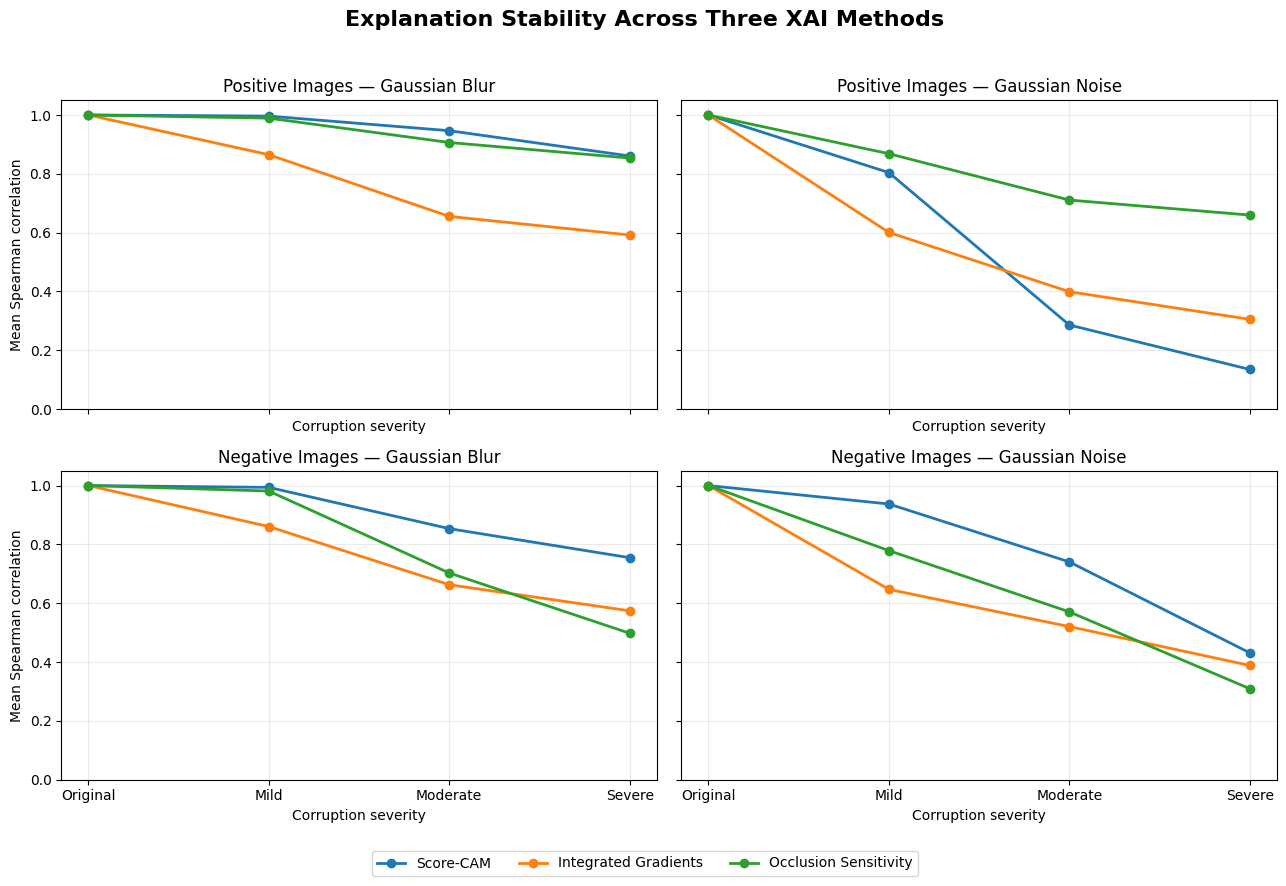

In [ ]:
severity_order = ["Original", "Mild", "Moderate", "Severe"]

method_colors = {
    "Score-CAM": "tab:blue",
    "Integrated Gradients": "tab:orange",
    "Occlusion Sensitivity": "tab:green",
}

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 9),
    sharex=True,
    sharey=True
)

for row_idx, pilot_group in enumerate(["Positive", "Negative"]):
    for col_idx, corruption in enumerate(["Blur", "Noise"]):

        ax = axes[row_idx, col_idx]

        subset = combined_stability[
            (combined_stability["pilot_group"] == pilot_group)
            & (combined_stability["corruption"] == corruption)
        ].copy()

        subset["severity"] = subset["condition"].apply(
            lambda x: "Original" if x == "Original" else x.split()[0]
        )

        for method in method_colors:
            method_data = subset[
                subset["method"] == method
            ].copy()

            method_data["severity"] = pd.Categorical(
                method_data["severity"],
                categories=severity_order,
                ordered=True
            )

            method_data = method_data.sort_values("severity")

            ax.plot(
                method_data["severity"].astype(str),
                method_data["mean_similarity"],
                marker="o",
                linewidth=2,
                color=method_colors[method],
                label=method
            )

        ax.set_title(f"{pilot_group} Images — Gaussian {corruption}")
        ax.set_xlabel("Corruption severity")
        ax.set_ylim(0, 1.05)
        ax.grid(alpha=0.25)

        if col_idx == 0:
            ax.set_ylabel("Mean Spearman correlation")

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=3,
    bbox_to_anchor=(0.5, 0.01)
)

fig.suptitle(
    "Explanation Stability Across Three XAI Methods",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0.06, 1, 0.96])

fig.savefig(
    COMPARISON_DIR / "xai_stability_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
severe_stability = combined_stability[
    combined_stability["condition"].isin(
        ["Severe Blur", "Severe Noise"]
    )
].copy()

severe_comparison = severe_stability.pivot_table(
    index=["corruption", "pilot_group"],
    columns="method",
    values="mean_similarity"
)

severe_comparison = severe_comparison.round(3)

display(severe_comparison)

severe_comparison.to_csv(
    COMPARISON_DIR / "severe_corruption_stability_comparison.csv"
)

method                  Integrated Gradients  Occlusion Sensitivity  Score-CAM
corruption pilot_group                                                        
Blur       Negative                    0.574                  0.498      0.755
           Positive                    0.592                  0.854      0.861
Noise      Negative                    0.389                  0.309      0.431
           Positive                    0.305                  0.660      0.135

In [ ]:
DATA_DIR = PROJECT_DIR / "Data"

print("CSV files in Data directory:")
for path in sorted(DATA_DIR.glob("*.csv")):
    print(path.name)

print("\nCSV files in Models directory:")
MODEL_DIR = PROJECT_DIR / "Models"

for path in sorted(MODEL_DIR.glob("*.csv")):
    print(path.name)

CSV files in Data directory:
model_dataset_split.csv
patient_ids_checkpoint.csv
pilot_selected_images.csv

CSV files in Models directory:
training_history.csv


In [ ]:
dataset_split = pd.read_csv(
    DATA_DIR / "model_dataset_split.csv"
)

print("Dataset shape:", dataset_split.shape)

print("\nColumns:")
print(dataset_split.columns.tolist())

print("\nFirst five rows:")
display(dataset_split.head())

print("\nSplit distribution:")
if "split" in dataset_split.columns:
    print(dataset_split["split"].value_counts())

Dataset shape: (29684, 8)

Columns:
['study_uid', 'series_uid', 'sop_uid', 'final_label', 'target', 'image_path', 'patient_id', 'split']

First five rows:


,study_uid,series_uid,sop_uid,final_label,target,image_path,patient_id,split
0,1.2.276.0.7230010.3.1.2.8323329.20779.15178744...,1.2.276.0.7230010.3.1.3.8323329.20779.15178744...,1.2.276.0.7230010.3.1.4.8323329.20779.15178744...,No Lung Opacity / Not Normal,0,/content/drive/MyDrive/XAI_project_Expo_1_fold...,3129f567-c659-42f8-b4e1-8a5e3827b477,train
1,1.2.276.0.7230010.3.1.2.8323329.19863.15178744...,1.2.276.0.7230010.3.1.3.8323329.19863.15178744...,1.2.276.0.7230010.3.1.4.8323329.19863.15178744...,No Lung Opacity / Not Normal,0,/content/drive/MyDrive/XAI_project_Expo_1_fold...,2d37e84a-0e82-4fc4-b20a-de306a63ca67,validation
2,1.2.276.0.7230010.3.1.2.8323329.12963.15178743...,1.2.276.0.7230010.3.1.3.8323329.12963.15178743...,1.2.276.0.7230010.3.1.4.8323329.12963.15178743...,No Lung Opacity / Not Normal,0,/content/drive/MyDrive/XAI_project_Expo_1_fold...,309c2bb5-826b-4e7d-9bdb-9808d9450064,train
3,1.2.276.0.7230010.3.1.2.8323329.29425.15178744...,1.2.276.0.7230010.3.1.3.8323329.29425.15178744...,1.2.276.0.7230010.3.1.4.8323329.29425.15178744...,No Lung Opacity / Not Normal,0,/content/drive/MyDrive/XAI_project_Expo_1_fold...,2fe3ba48-ce4d-42a4-8eda-99e3eb40d5fe,train
4,1.2.276.0.7230010.3.1.2.8323329.13765.15178743...,1.2.276.0.7230010.3.1.3.8323329.13765.15178743...,1.2.276.0.7230010.3.1.4.8323329.13765.15178743...,No Lung Opacity / Not Normal,0,/content/drive/MyDrive/XAI_project_Expo_1_fold...,30a4932f-d7b3-4727-b0bc-72605b530913,train



Split distribution:
split
train         20778
validation     4453
test           4453
Name: count, dtype: int64


In [ ]:
test_data = dataset_split[
    dataset_split["split"].astype(str).str.lower() == "test"
].copy()

print("Test images:", len(test_data))

print("\nAvailable columns:")
print(test_data.columns.tolist())

print("\nSample test records:")
display(test_data.head(3))

print("\nMissing values by column:")
print(test_data.isna().sum())

Test images: 4453

Available columns:
['study_uid', 'series_uid', 'sop_uid', 'final_label', 'target', 'image_path', 'patient_id', 'split']

Sample test records:


,study_uid,series_uid,sop_uid,final_label,target,image_path,patient_id,split
18,1.2.276.0.7230010.3.1.2.8323329.7667.151787433...,1.2.276.0.7230010.3.1.3.8323329.7667.151787433...,1.2.276.0.7230010.3.1.4.8323329.7667.151787433...,No Lung Opacity / Not Normal,0,/content/drive/MyDrive/XAI_project_Expo_1_fold...,2c18260b-22c7-4f05-9f43-9867ba93b519,test
53,1.2.276.0.7230010.3.1.2.8323329.25694.15178744...,1.2.276.0.7230010.3.1.3.8323329.25694.15178744...,1.2.276.0.7230010.3.1.4.8323329.25694.15178744...,No Lung Opacity / Not Normal,0,/content/drive/MyDrive/XAI_project_Expo_1_fold...,c1696635-dfc2-4215-ac85-46825953fc82,test
55,1.2.276.0.7230010.3.1.2.8323329.30900.15178745...,1.2.276.0.7230010.3.1.3.8323329.30900.15178745...,1.2.276.0.7230010.3.1.4.8323329.30900.15178745...,No Lung Opacity / Not Normal,0,/content/drive/MyDrive/XAI_project_Expo_1_fold...,c1d9b4c9-39cc-4b37-b95b-82d26a1b68df,test



Missing values by column:
study_uid      0
series_uid     0
sop_uid        0
final_label    0
target         0
image_path     0
patient_id     0
split          0
dtype: int64


In [ ]:
print("Test-set label distribution:")
print(test_data["target"].value_counts().sort_index())

print("\nUnique patients by class:")
print(
    test_data.groupby("target")["patient_id"].nunique()
)

print("\nDuplicate image identifiers:")
print(test_data["sop_uid"].duplicated().sum())

print("\nPatients appearing in both classes:")
positive_patients = set(
    test_data.loc[test_data["target"] == 1, "patient_id"]
)
negative_patients = set(
    test_data.loc[test_data["target"] == 0, "patient_id"]
)

print(len(positive_patients & negative_patients))

Test-set label distribution:
target
0    3387
1    1066
Name: count, dtype: int64

Unique patients by class:
target
0    3387
1    1066
Name: patient_id, dtype: int64

Duplicate image identifiers:
0

Patients appearing in both classes:
0


In [ ]:
!pip install pydicom

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 45.4 MB/s eta 0:00:00


In [ ]:
DATA_DIR = PROJECT_DIR / "Data"
test_data = pd.read_csv(DATA_DIR / "model_dataset_split.csv")
test_data = test_data[test_data["split"] == "test"].copy()

import json
import sys

sys.path.insert(0, str(PROJECT_DIR))

from xai_utils import build_opacity_lookup

annotation_path = (
    DATA_DIR /
    "pneumonia-challenge-annotations-adjudicated-kaggle_2018.json"
)

with open(annotation_path, "r") as f:
    annotations = json.load(f)

annotation_records = annotations["datasets"][0]["annotations"]

opacity_lookup = build_opacity_lookup(annotation_records)

positive_test = test_data[
    test_data["target"] == 1
].copy()

positive_test["n_boxes"] = (
    positive_test["sop_uid"]
    .astype(str)
    .map(lambda uid: len(opacity_lookup.get(uid, [])))
)

print("Total positive test images:", len(positive_test))

print(
    "Positive images with annotations:",
    (positive_test["n_boxes"] > 0).sum()
)

print(
    "Positive images without annotations:",
    (positive_test["n_boxes"] == 0).sum()
)

print("\nBounding-box counts:")
print(positive_test["n_boxes"].value_counts().sort_index())

Total positive test images: 1066
Positive images with annotations: 1066
Positive images without annotations: 0

Bounding-box counts:
n_boxes
1    455
2    581
3     29
4      1
Name: count, dtype: int64



## 2. Expanded Evaluation Sample

The expanded evaluation uses 300 held-out chest X-rays selected from the test split:

- 150 lung-opacity-positive images with radiologist-annotated bounding boxes.
- 150 lung-opacity-negative images.

The saved sample manifest is `Results/ExpandedEvaluation/expanded_sample_300.csv`.

### Sample Validation

The following cells verify that:

- Every selected image belongs to the held-out test split.
- Image and patient identifiers are unique within the selected sample.
- The sample contains equal numbers of positive and negative images.
- All selected positive images have available opacity bounding-box annotations.

### Evaluation Scope

All 300 images contribute to the explanation-stability comparisons.

Localization alignment is evaluated only for the 150 annotated positive images because the metric requires an opacity-region reference.

The 300-image sample is larger than the 12-image pilot used in the individual XAI notebooks.

The sample is held out from model training, but it is not an external clinical validation cohort.


In [ ]:
EXPANDED_DIR = RESULTS_DIR / "ExpandedEvaluation"

expanded_sample = pd.read_csv(
    EXPANDED_DIR / "expanded_sample_300.csv"
)

print("Loaded images:", len(expanded_sample))
print(expanded_sample["image_group"].value_counts())

Loaded images: 300
image_group
Negative    150
Positive    150
Name: count, dtype: int64


In [ ]:
# Ensure every selected image belongs to the test set
assert (expanded_sample["split"] == "test").all()

# Ensure unique image and patient identifiers
assert expanded_sample["sop_uid"].is_unique
assert expanded_sample["patient_id"].is_unique

# Ensure balanced classes
assert (expanded_sample["target"] == 1).sum() == 150
assert (expanded_sample["target"] == 0).sum() == 150

# Ensure every selected positive image has annotations
selected_positive = expanded_sample[
    expanded_sample["target"] == 1
]

assert all(
    len(opacity_lookup.get(str(uid), [])) > 0
    for uid in selected_positive["sop_uid"]
)

print("All sampling checks passed!")

print("\nSaved sample manifest:")
print(EXPANDED_DIR / "expanded_sample_300.csv")

All sampling checks passed!

Saved sample manifest:
/content/drive/MyDrive/XAI_project_Expo_1_folder/Results/ExpandedEvaluation/expanded_sample_300.csv


In [ ]:
import sys
import time
import torch

sys.path.insert(0, str(PROJECT_DIR))

from xai_utils import (
    load_trained_model,
    load_dicom,
    resize_image,
    prepare_corrupted_image,
)

MODEL_DIR = PROJECT_DIR / "Models"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = load_trained_model(
    MODEL_DIR / "resnet50_best.pth",
    device
)

model.eval()

# Prevent model parameters from being updated
for parameter in model.parameters():
    parameter.requires_grad_(False)

print("Device:", device)
print("Model training mode:", model.training)
print(
    "Trainable parameters:",
    sum(p.requires_grad for p in model.parameters())
)

Device: cuda
Model training mode: False
Trainable parameters: 0


In [ ]:
# Use one positive and one negative image for benchmarking
benchmark_images = pd.concat(
    [
        expanded_sample[expanded_sample["target"] == 1].head(1),
        expanded_sample[expanded_sample["target"] == 0].head(1),
    ],
    ignore_index=True
)

print("Benchmark cases:")
display(
    benchmark_images[
        ["sample_number", "image_group", "sop_uid", "target"]
    ]
)

for _, row in benchmark_images.iterrows():
    image_path = Path(row["image_path"])

    print(
        row["image_group"],
        "| File exists:",
        image_path.exists()
    )

Benchmark cases:


,sample_number,image_group,sop_uid,target
0,4,Positive,1.2.276.0.7230010.3.1.4.8323329.1684.151787429...,1
1,1,Negative,1.2.276.0.7230010.3.1.4.8323329.6185.151787432...,0


Positive | File exists: True
Negative | File exists: True


In [ ]:
import pydicom
import torch
import time

print("Model type:", type(model).__name__)

print("\nCheckpoint device:", device)

print("\nBenchmark DICOM information:")
for _, row in benchmark_images.iterrows():
    ds = pydicom.dcmread(str(row["image_path"]), stop_before_pixels=True)

    print(
        row["image_group"],
        "| Rows:", ds.Rows,
        "| Columns:", ds.Columns,
        "| Photometric:", ds.PhotometricInterpretation
    )

Model type: ResNet

Checkpoint device: cuda

Benchmark DICOM information:
Positive | Rows: 1024 | Columns: 1024 | Photometric: MONOCHROME2
Negative | Rows: 1024 | Columns: 1024 | Photometric: MONOCHROME2


In [ ]:
import inspect
import xai_utils

available_functions = [
    name
    for name, obj in inspect.getmembers(xai_utils)
    if inspect.isfunction(obj)
]

print("Functions available in xai_utils.py:\n")

for name in available_functions:
    print("-", name)

ModuleNotFoundError: No module named 'xai_utils'

In [ ]:
NOTEBOOKS_DIR = PROJECT_DIR / "Python Notebooks"

print("Notebook directory exists:", NOTEBOOKS_DIR.exists())

for notebook in sorted(NOTEBOOKS_DIR.glob("*.ipynb")):
    print(notebook.name)

Notebook directory exists: True
01_RSNA_Data_Preparation.ipynb
02_ResNet50_Training.ipynb
03_Score-CAM.ipynb
04_Integrated_Gradients.ipynb
05_Occlusion_Sensitivity.ipynb
06_XAI_Comparison.ipynb
Copy of 06_XAI_Comparison.ipynb


In [ ]:
import json
import re

for notebook_path in sorted(NOTEBOOKS_DIR.glob("*.ipynb")):

    if not notebook_path.name.startswith(("03", "04", "05")):
        continue

    print(f"\n--- {notebook_path.name} ---")

    with open(notebook_path, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    for cell_index, cell in enumerate(notebook["cells"]):

        if cell["cell_type"] != "code":
            continue

        source = "".join(cell["source"])

        definitions = re.findall(
            r"^(?:def|class)\s+([A-Za-z_]\w*)",
            source,
            flags=re.MULTILINE
        )

        for name in definitions:
            print(f"Cell {cell_index}: {name}")


--- 03_Score-CAM.ipynb ---
Cell 7: load_dicom
Cell 7: MedicalImageTransform
Cell 15: PositiveClassTarget
Cell 33: prepare_corrupted_image
Cell 36: calculate_alignment
Cell 44: show_memory
Cell 51: NegativeClassTarget
Cell 64: apply_gaussian_noise
Cell 78: load_dicom
Cell 78: MedicalImageTransform
Cell 78: prepare_corrupted_image
Cell 78: resize_image
Cell 78: apply_gaussian_blur
Cell 78: apply_gaussian_noise
Cell 78: build_opacity_lookup
Cell 78: calculate_alignment
Cell 78: load_trained_model

--- 04_Integrated_Gradients.ipynb ---
Cell 4: forward_func
Cell 15: generate_ig_explanation

--- 05_Occlusion_Sensitivity.ipynb ---
Cell 15: generate_occlusion_map


In [ ]:
import json

cells_to_inspect = {
    "03_Score-CAM.ipynb": [15, 51],
    "04_Integrated_Gradients.ipynb": [4, 15],
    "05_Occlusion_Sensitivity.ipynb": [15],
}

for filename, cell_numbers in cells_to_inspect.items():

    notebook_path = NOTEBOOKS_DIR / filename

    with open(notebook_path, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    print(f"\n{'=' * 70}")
    print(filename)
    print("=" * 70)

    for cell_number in cell_numbers:

        cell = notebook["cells"][cell_number]

        print(f"\n--- Cell {cell_number} ---")
        print("".join(cell["source"]))


03_Score-CAM.ipynb

--- Cell 15 ---
import time

class PositiveClassTarget:
    def __call__(self, model_output):
        return model_output.reshape(-1)[0]

start_time = time.time()

heatmap = cam(
    input_tensor=input_batch,
    targets=[PositiveClassTarget()]
)[0]

elapsed = time.time() - start_time

print("Heatmap shape:", heatmap.shape)
print(f"Score-CAM runtime: {elapsed:.1f} seconds")
print("Heatmap range:", heatmap.min(), heatmap.max())

--- Cell 51 ---
# Score-CAM target for the negative class
class NegativeClassTarget:
    def __call__(self, model_output):
        return -model_output.reshape(-1)[0]


negative_target = [NegativeClassTarget()]

# Use a smaller batch size to reduce peak memory usage
cam.batch_size = 4

print("Negative-class Score-CAM target ready.")
print("Score-CAM batch size:", cam.batch_size)

04_Integrated_Gradients.ipynb

--- Cell 4 ---
from captum.attr import IntegratedGradients

# Use the model's raw logit output
def forward_func(x):
    return model(

In [ ]:
%pip install -q grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 2.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
from pytorch_grad_cam import ScoreCAM

class PositiveClassTarget:
    def __call__(self, model_output):
        return model_output.reshape(-1)[0]

class NegativeClassTarget:
    def __call__(self, model_output):
        return -model_output.reshape(-1)[0]

cam = ScoreCAM(
    model=model,
    target_layers=[model.layer4[-1]]
)

cam.batch_size = 4

print("Score-CAM ready.")
print("Target layer:", model.layer4[-1].__class__.__name__)
print("Batch size:", cam.batch_size)

Score-CAM ready.
Target layer: Bottleneck
Batch size: 4


In [ ]:
import time

row = benchmark_images.iloc[0]

image = load_dicom(row["image_path"])
resized = resize_image(image)

tensor = (
    prepare_corrupted_image(resized)
    .unsqueeze(0)
    .to(device)
)

with torch.no_grad():
    probability = torch.sigmoid(
        model(tensor).flatten()[0]
    ).item()

predicted_class = int(probability >= 0.5)

target = (
    PositiveClassTarget()
    if predicted_class == 1
    else NegativeClassTarget()
)

if device.type == "cuda":
    torch.cuda.synchronize()

start = time.perf_counter()

heatmap = cam(
    input_tensor=tensor,
    targets=[target]
)[0].copy()

if device.type == "cuda":
    torch.cuda.synchronize()

elapsed = time.perf_counter() - start

print("True class:", int(row["target"]))
print("Predicted class:", predicted_class)
print("Opacity probability:", round(probability, 4))
print("Score-CAM runtime:", round(elapsed, 2), "seconds")
print("Heatmap shape:", heatmap.shape)

100%|██████████| 512/512 [00:21<00:00, 24.09it/s]

True class: 1
Predicted class: 1
Opacity probability: 0.9332
Score-CAM runtime: 21.41 seconds
Heatmap shape: (320, 384)


In [ ]:
%pip install -q captum

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 12.4 MB/s eta 0:00:00


In [ ]:
from captum.attr import IntegratedGradients

IG_STEPS = 32
IG_INTERNAL_BATCH_SIZE = 4

def forward_func(x):
    return model(x).squeeze(1)

def generate_ig_explanation(resized_image, target_class=1):
    x = prepare_corrupted_image(
        resized_image
    ).unsqueeze(0).to(device)

    black_baseline = prepare_corrupted_image(
        np.zeros_like(resized_image, dtype=np.float32)
    ).unsqueeze(0).to(device)

    sign = 1 if target_class == 1 else -1

    def target_forward(inputs):
        return sign * forward_func(inputs)

    ig = IntegratedGradients(target_forward)

    attr, delta = ig.attribute(
        x,
        baselines=black_baseline,
        n_steps=IG_STEPS,
        internal_batch_size=IG_INTERNAL_BATCH_SIZE,
        return_convergence_delta=True
    )

    signed_map = attr.detach().cpu().numpy()[0].sum(axis=0)

    return {
        "signed_map": signed_map,
        "magnitude_map": np.abs(signed_map),
        "convergence_delta": delta.item()
    }

print("Integrated Gradients ready!")

Integrated Gradients ready!


In [ ]:
import time

if device.type == "cuda":
    torch.cuda.synchronize()

start = time.perf_counter()

ig_result = generate_ig_explanation(
    resized,
    target_class=predicted_class
)

if device.type == "cuda":
    torch.cuda.synchronize()

ig_elapsed = time.perf_counter() - start

print(f"Integrated Gradients runtime: {ig_elapsed:.2f} seconds")
print("Attribution shape:", ig_result["magnitude_map"].shape)
print("Convergence delta:", ig_result["convergence_delta"])

Integrated Gradients runtime: 1.23 seconds
Attribution shape: (320, 384)
Convergence delta: -0.009891629219055176


In [ ]:
import json
import ast

occlusion_notebook_path = (
    NOTEBOOKS_DIR / "05_Occlusion_Sensitivity.ipynb"
)

with open(occlusion_notebook_path, "r", encoding="utf-8") as f:
    occlusion_notebook = json.load(f)

function_source = None

for cell in occlusion_notebook["cells"]:
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    # Skip cells that don't define our function
    if "def generate_occlusion_map(" not in source:
        continue

    tree = ast.parse(source)

    for node in tree.body:
        if (
            isinstance(node, ast.FunctionDef)
            and node.name == "generate_occlusion_map"
        ):
            function_source = ast.get_source_segment(source, node)
            break

    if function_source is not None:
        break

assert function_source is not None, "Occlusion function not found"

exec(function_source)

print("Occlusion Sensitivity function loaded successfully!")

Occlusion Sensitivity function loaded successfully!


In [ ]:
if device.type == "cuda":
    torch.cuda.synchronize()

start = time.perf_counter()

occlusion_map, original_logit = generate_occlusion_map(
    image=resized,
    model=model,
    device=device,
    target_class=predicted_class,
    window_size=32,
    stride=16,
    batch_size=32
)

if device.type == "cuda":
    torch.cuda.synchronize()

occlusion_elapsed = time.perf_counter() - start

print(
    f"Occlusion Sensitivity runtime: {occlusion_elapsed:.2f} seconds"
)

print("Occlusion map shape:", occlusion_map.shape)
print("Original logit:", round(original_logit, 4))

Occlusion Sensitivity runtime: 5.20 seconds
Occlusion map shape: (320, 384)
Original logit: 2.6371


In [ ]:
EXPANDED_DIR = RESULTS_DIR / "ExpandedEvaluation"

EXPANDED_SCORECAM_DIR = EXPANDED_DIR / "ScoreCAM"
EXPANDED_IG_DIR = EXPANDED_DIR / "IntegratedGradients"
EXPANDED_OCCLUSION_DIR = EXPANDED_DIR / "OcclusionSensitivity"

for directory in [
    EXPANDED_SCORECAM_DIR,
    EXPANDED_IG_DIR,
    EXPANDED_OCCLUSION_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

print("Expanded evaluation directories ready!")

for directory in [
    EXPANDED_SCORECAM_DIR,
    EXPANDED_IG_DIR,
    EXPANDED_OCCLUSION_DIR
]:
    print(directory)

Expanded evaluation directories ready!
/content/drive/MyDrive/XAI_project_Expo_1_folder/Results/ExpandedEvaluation/ScoreCAM
/content/drive/MyDrive/XAI_project_Expo_1_folder/Results/ExpandedEvaluation/IntegratedGradients
/content/drive/MyDrive/XAI_project_Expo_1_folder/Results/ExpandedEvaluation/OcclusionSensitivity



## 3. Shared Experimental Protocol

The three explanation methods are evaluated using the same model checkpoint, image sample, corruption conditions, and prediction target convention.

### Corruption Conditions

| Condition | Parameter |
|---|---|
| Original | No corruption |
| Mild Gaussian blur | Sigma = 0.5 |
| Moderate Gaussian blur | Sigma = 1.5 |
| Severe Gaussian blur | Sigma = 3.0 |
| Mild Gaussian noise | Sigma = 0.02 |
| Moderate Gaussian noise | Sigma = 0.05 |
| Severe Gaussian noise | Sigma = 0.10 |

Gaussian noise generation uses a fixed seed of 42.

### Explanation Target

For each image, the original model prediction determines the target class used by the explanation methods.

The same target is retained for the corresponding corrupted images, even if the predicted class changes.

This allows the analysis to compare explanations for a consistent target rather than changing the explanation target across corruption conditions.

### Evaluation Size

Each method produces seven evaluations per image: one original reference and six corrupted conditions.

- 300 images × 7 conditions = 2,100 evaluations per method.
- 3 methods × 2,100 evaluations = 6,300 evaluations across the full expanded sample.
- 150 annotated positive images × 3 methods × 6 corruptions = 2,700 evaluations in the primary disagreement audit.

These are repeated method-image-condition evaluations, not 2,700 independent patients.


In [ ]:
CORRUPTION_CONDITIONS = [
    ("Original", None, None),
    ("Blur", "mild", 0.5),
    ("Blur", "moderate", 1.5),
    ("Blur", "severe", 3.0),
    ("Noise", "mild", 0.02),
    ("Noise", "moderate", 0.05),
    ("Noise", "severe", 0.10),
]

print("Number of conditions:", len(CORRUPTION_CONDITIONS))

for condition in CORRUPTION_CONDITIONS:
    print(condition)

Number of conditions: 7
('Original', None, None)
('Blur', 'mild', 0.5)
('Blur', 'moderate', 1.5)
('Blur', 'severe', 3.0)
('Noise', 'mild', 0.02)
('Noise', 'moderate', 0.05)
('Noise', 'severe', 0.1)


In [ ]:
import inspect

print("resize_image:")
print(inspect.signature(resize_image))

print("\napply_gaussian_blur:")
print(inspect.signature(xai_utils.apply_gaussian_blur))

print("\napply_gaussian_noise:")
print(inspect.signature(xai_utils.apply_gaussian_noise))

print("\nload_dicom:")
print(inspect.signature(load_dicom))

resize_image:
(image)

apply_gaussian_blur:
(image, sigma)

apply_gaussian_noise:
(image, sigma, seed=42)

load_dicom:
(path)


In [ ]:
from xai_utils import apply_gaussian_blur, apply_gaussian_noise

def create_corrupted_image(image, corruption, severity, sigma):
    if corruption == "Original":
        return image.copy()

    if corruption == "Blur":
        return apply_gaussian_blur(image, sigma=sigma)

    if corruption == "Noise":
        return apply_gaussian_noise(image, sigma=sigma, seed=42)

    raise ValueError(f"Unknown corruption: {corruption}")


def get_model_prediction(image):
    tensor = (
        prepare_corrupted_image(image)
        .unsqueeze(0)
        .to(device)
    )

    with torch.no_grad():
        logit = model(tensor).flatten()[0]
        probability = torch.sigmoid(logit).item()

    predicted_class = int(probability >= 0.5)

    return probability, predicted_class


print("Corruption and prediction functions ready!")

Corruption and prediction functions ready!


In [ ]:
import time
from scipy.stats import spearmanr

IG_TEST_DIR = EXPANDED_IG_DIR / "TestBatch"
IG_TEST_DIR.mkdir(parents=True, exist_ok=True)

test_images = pd.concat([
    expanded_sample[expanded_sample["target"] == 1].head(1),
    expanded_sample[expanded_sample["target"] == 0].head(1)
], ignore_index=True)

for _, row in test_images.iterrows():

    uid = str(row["sop_uid"])
    output_file = IG_TEST_DIR / f"{uid}.csv"

    if output_file.exists():
        print("Skipping completed image:", uid)
        continue

    image = resize_image(load_dicom(row["image_path"]))

    original_probability, original_prediction = (
        get_model_prediction(image)
    )

    records = []
    original_map = None

    start_time = time.perf_counter()

    for corruption, severity, sigma in CORRUPTION_CONDITIONS:

        corrupted_image = create_corrupted_image(
            image, corruption, severity, sigma
        )

        result = generate_ig_explanation(
            corrupted_image,
            target_class=original_prediction
        )

        if corruption == "Original":
            original_map = result["magnitude_map"]
            similarity = 1.0
        else:
            similarity = spearmanr(
                original_map.ravel(),
                result["magnitude_map"].ravel()
            ).statistic

        probability, predicted_class = (
            get_model_prediction(corrupted_image)
        )

        records.append({
            "sop_uid": uid,
            "true_class": int(row["target"]),
            "original_predicted_class": original_prediction,
            "corrupted_predicted_class": predicted_class,
            "corruption": corruption,
            "severity": severity or "original",
            "sigma": sigma,
            "opacity_probability": probability,
            "explanation_similarity": similarity,
            "convergence_delta": result["convergence_delta"]
        })

    pd.DataFrame(records).to_csv(output_file, index=False)

    elapsed = time.perf_counter() - start_time

    print(
        f"Completed {row['image_group']} image "
        f"in {elapsed:.1f} seconds"
    )

print("\nTest batch finished!")

Completed Positive image in 7.6 seconds
Completed Negative image in 5.4 seconds

Test batch finished!


In [ ]:
import inspect

print(inspect.getsource(xai_utils.calculate_alignment))

print("\nOpacity lookup example:")
example_uid = str(
    expanded_sample.loc[
        expanded_sample["target"] == 1, "sop_uid"
    ].iloc[0]
)

print("Image ID:", example_uid)
print("Annotations:", opacity_lookup.get(example_uid, []))

def calculate_alignment(cam_map, boxes):
    h, w = cam_map.shape
    mask = np.zeros((h, w), dtype=bool)

    for record in boxes:
        box = record["data"]

        sx = w / record["width"]
        sy = h / record["height"]

        x1 = int(np.floor(box["x"] * sx))
        y1 = int(np.floor(box["y"] * sy))
        x2 = int(np.ceil((box["x"] + box["width"]) * sx))
        y2 = int(np.ceil((box["y"] + box["height"]) * sy))

        x1, x2 = np.clip([x1, x2], 0, w)
        y1, y2 = np.clip([y1, y2], 0, h)

        mask[y1:y2, x1:x2] = True

    total = cam_map.sum()

    return (
        float(cam_map[mask].sum() / total)
        if total > 0 else np.nan
    )


Opacity lookup example:
Image ID: 1.2.276.0.7230010.3.1.4.8323329.1684.1517874292.301663
Annotations: [{'id': 'A_enl570', 'createdAt': '2018-07-03T22:59:39.879Z', 'createdById': 'U_1z6', 'updatedAt': '2018-07-03T22:59:39.884Z', 'updatedById': 'U_1z6', 'machineLearningModelId': None, 'StudyInstanceUID': '1.2.276.0.7230010.3.1

In [ ]:
from xai_utils import calculate_alignment

print("Localization function imported successfully!")

Localization function imported successfully!


In [ ]:
positive_row = expanded_sample[
    expanded_sample["target"] == 1
].iloc[0]

positive_uid = str(positive_row["sop_uid"])

positive_image = resize_image(
    load_dicom(positive_row["image_path"])
)

positive_probability, positive_prediction = (
    get_model_prediction(positive_image)
)

positive_ig = generate_ig_explanation(
    positive_image,
    target_class=positive_prediction
)

positive_boxes = opacity_lookup.get(positive_uid, [])

positive_alignment = calculate_alignment(
    positive_ig["magnitude_map"],
    positive_boxes
)

print("True class:", positive_row["target"])
print("Predicted class:", positive_prediction)
print("Opacity probability:", round(positive_probability, 4))
print("Number of bounding boxes:", len(positive_boxes))
print("Localization alignment:", round(positive_alignment, 4))

True class: 1
Predicted class: 1
Opacity probability: 0.9332
Number of bounding boxes: 2
Localization alignment: 0.3468


In [ ]:
test_files = sorted(IG_TEST_DIR.glob("*.csv"))

print("Saved test files:", len(test_files))

test_results = pd.concat(
    [pd.read_csv(path) for path in test_files],
    ignore_index=True
)

print("Total explanation records:", len(test_results))

display(
    test_results[
        [
            "true_class",
            "corruption",
            "severity",
            "opacity_probability",
            "explanation_similarity"
        ]
    ]
)

Saved test files: 2
Total explanation records: 14


,true_class,corruption,severity,opacity_probability,explanation_similarity
0,1,Original,original,0.933209,1.000000
1,1,Blur,mild,0.938439,0.879814
2,1,Blur,moderate,0.917127,0.707987
3,1,Blur,severe,0.891835,0.677471
4,1,Noise,mild,0.884758,0.720750
5,1,Noise,moderate,0.664113,0.621231
6,1,Noise,severe,0.634156,0.456002
7,0,Original,original,0.815852,1.000000
8,0,Blur,mild,0.805532,0.898182
9,0,Blur,moderate,0.740457,0.785589


In [ ]:
%pip install -q captum grad-cam pydicom

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 4.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 18.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 84.2 MB/s eta 0:00:00


In [ ]:
import gc
import psutil
import torch

IG_STEPS = 32
IG_INTERNAL_BATCH_SIZE = 4

required_names = [
    "model",
    "device",
    "expanded_sample",
    "opacity_lookup",
    "generate_ig_explanation",
    "CORRUPTION_CONDITIONS",
    "create_corrupted_image",
    "get_model_prediction",
    "calculate_alignment",
    "IG_FULL_DIR"
]

missing = [name for name in required_names if name not in globals()]

if missing:
    print("Missing setup variables/functions:")
    print(missing)
else:
    print("All required functions and variables are ready!")
    print("Images in sample:", len(expanded_sample))
    print("Completed images:", len(list(IG_FULL_DIR.glob("*.csv"))))
    print("Available RAM:", round(psutil.virtual_memory().available / 1024**3, 2), "GB")
    print("IG internal batch size:", IG_INTERNAL_BATCH_SIZE)

All required functions and variables are ready!
Images in sample: 300
Completed images: 15
Available RAM: 10.21 GB
IG internal batch size: 4


In [ ]:
import sys
import numpy as np
import pandas as pd
import torch
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/XAI_project_Expo_1_folder"
)
RESULTS_DIR = PROJECT_DIR / "Results"
EXPANDED_DIR = RESULTS_DIR / "ExpandedEvaluation"
EXPANDED_IG_DIR = EXPANDED_DIR / "IntegratedGradients"
IG_FULL_DIR = EXPANDED_IG_DIR / "Full300"

sys.path.insert(0, str(PROJECT_DIR))

from xai_utils import (
    load_trained_model,
    load_dicom,
    resize_image,
    prepare_corrupted_image,
    apply_gaussian_blur,
    apply_gaussian_noise,
    build_opacity_lookup,
    calculate_alignment
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = load_trained_model(
    PROJECT_DIR / "Models" / "resnet50_best.pth",
    device
)
model.eval()

for parameter in model.parameters():
    parameter.requires_grad_(False)

expanded_sample = pd.read_csv(
    EXPANDED_DIR / "expanded_sample_300.csv"
)

print("Model restored:", device)
print("Expanded sample:", len(expanded_sample))
print("Saved images:", len(list(IG_FULL_DIR.glob("*.csv"))))

Model restored: cuda
Expanded sample: 300
Saved images: 300



## 4. Expanded Integrated Gradients Evaluation

This section generates Integrated Gradients explanations for the 300-image held-out sample.

For each image, the notebook evaluates the original image and six corrupted versions using the same fixed model and original predicted-class target.

The experiment records:

- Explanation stability relative to the original attribution map.
- Localization alignment for annotated positive images.
- Original and corrupted predicted classes.
- Lung-opacity prediction probability.
- Integrated Gradients convergence delta.

Results are saved as individual image-level CSV files to support recovery from interrupted Colab sessions.

The batch limit controls how many previously unprocessed images are evaluated during a single execution. It does not change the intended 300-image sample.


In [ ]:

import gc
import time
import psutil
import numpy as np
import pandas as pd
import torch
from scipy.stats import spearmanr

IG_FULL_DIR = EXPANDED_IG_DIR / "Full300"
IG_FULL_DIR.mkdir(parents=True, exist_ok=True)

BATCH_LIMIT = 50
processed_this_run = 0

start_time = time.perf_counter()

for image_number, (_, row) in enumerate(expanded_sample.iterrows(), start=1):

    uid = str(row["sop_uid"])
    output_file = IG_FULL_DIR / f"{uid}.csv"

    # Preserve previously completed results
    if output_file.exists():
        continue

    # Stop after 10 NEW images
    if processed_this_run >= BATCH_LIMIT:
        break

    image = resize_image(load_dicom(row["image_path"]))
    true_class = int(row["target"])

    original_probability, original_prediction = get_model_prediction(image)
    original_correct = int(original_prediction == true_class)

    boxes = opacity_lookup.get(uid, []) if true_class == 1 else []

    records = []
    original_map = None

    for corruption, severity, sigma in CORRUPTION_CONDITIONS:

        corrupted_image = create_corrupted_image(
            image, corruption, severity, sigma
        )

        result = generate_ig_explanation(
            corrupted_image,
            target_class=original_prediction
        )

        magnitude_map = result["magnitude_map"]

        if corruption == "Original":
            original_map = magnitude_map
            similarity = 1.0
        else:
            similarity = spearmanr(
                original_map.ravel(),
                magnitude_map.ravel()
            ).statistic

        probability, prediction = get_model_prediction(corrupted_image)

        alignment = (
            calculate_alignment(magnitude_map, boxes)
            if true_class == 1 and len(boxes) > 0
            else np.nan
        )

        records.append({
            "sop_uid": uid,
            "true_class": true_class,
            "original_predicted_class": original_prediction,
            "original_correct": original_correct,
            "corrupted_predicted_class": prediction,
            "prediction_changed": int(prediction != original_prediction),
            "corruption": corruption,
            "severity": severity or "original",
            "sigma": sigma,
            "opacity_probability": probability,
            "explanation_similarity": similarity,
            "localization_alignment": alignment,
            "n_boxes": len(boxes),
            "convergence_delta": result["convergence_delta"]
        })

        # Release temporary attribution arrays
        del result, magnitude_map, corrupted_image

    # Save one CSV per image, using an atomic replacement
    temporary_file = output_file.with_suffix(".tmp")
    pd.DataFrame(records).to_csv(temporary_file, index=False)
    temporary_file.replace(output_file)

    processed_this_run += 1

    # Release image-level arrays
    del image, original_map, records, boxes
    gc.collect()

    if device.type == "cuda":
        torch.cuda.empty_cache()

    ram = psutil.virtual_memory()

    print(
        f"Completed {processed_this_run}/{BATCH_LIMIT} new images | "
        f"Overall: {len(list(IG_FULL_DIR.glob('*.csv')))}/300 | "
        f"RAM: {ram.percent:.1f}% | "
        f"Available: {ram.available / 1024**3:.2f} GB",
        flush=True
    )

elapsed = time.perf_counter() - start_time

print(f"\nBatch finished in {elapsed / 60:.1f} minutes.")
print(f"Total completed: {len(list(IG_FULL_DIR.glob('*.csv')))}/300")

Completed 1/50 new images | Overall: 251/300 | RAM: 22.6% | Available: 9.80 GB
Completed 2/50 new images | Overall: 252/300 | RAM: 22.7% | Available: 9.80 GB
Completed 3/50 new images | Overall: 253/300 | RAM: 22.8% | Available: 9.79 GB
Completed 4/50 new images | Overall: 254/300 | RAM: 22.6% | Available: 9.81 GB
Completed 5/50 new images | Overall: 255/300 | RAM: 22.7% | Available: 9.80 GB
Completed 6/50 new images | Overall: 256/300 | RAM: 22.6% | Available: 9.80 GB
Completed 7/50 new images | Overall: 257/300 | RAM: 22.7% | Available: 9.80 GB
Completed 8/50 new images | Overall: 258/300 | RAM: 22.7% | Available: 9.80 GB
Completed 9/50 new images | Overall: 259/300 | RAM: 22.8% | Available: 9.78 GB
Completed 10/50 new images | Overall: 260/300 | RAM: 22.8% | Available: 9.78 GB
Completed 11/50 new images | Overall: 261/300 | RAM: 22.7% | Available: 9.80 GB
Completed 12/50 new images | Overall: 262/300 | RAM: 22.7% | Available: 9.80 GB
Completed 13/50 new images | Overall: 263/300 | R

In [ ]:
ig_files = sorted(IG_FULL_DIR.glob("*.csv"))

ig_full_results = pd.concat(
    [pd.read_csv(file) for file in ig_files],
    ignore_index=True
)

print("Completed image files:", len(ig_files))
print("Total explanation records:", len(ig_full_results))
print("Unique images:", ig_full_results["sop_uid"].nunique())

print("\nRecords by corruption:")
print(
    ig_full_results.groupby(
        ["corruption", "severity"]
    ).size()
)

assert len(ig_files) == 300
assert len(ig_full_results) == 2100
assert ig_full_results["sop_uid"].nunique() == 300
assert ig_full_results.groupby("sop_uid").size().eq(7).all()

output_path = EXPANDED_IG_DIR / "ig_expanded_results.csv"
ig_full_results.to_csv(output_path, index=False)

print("\nValidation passed!")
print("Combined results saved to:", output_path)

Completed image files: 300
Total explanation records: 2100
Unique images: 300

Records by corruption:
corruption  severity
Blur        mild        300
            moderate    300
            severe      300
Noise       mild        300
            moderate    300
            severe      300
Original    original    300
dtype: int64

Validation passed!
Combined results saved to: /content/drive/MyDrive/XAI_project_Expo_1_folder/Results/ExpandedEvaluation/IntegratedGradients/ig_expanded_results.csv


In [ ]:
IG_FULL_DIR = Path(
    "/content/drive/MyDrive/XAI_project_Expo_1_folder/"
    "Results/ExpandedEvaluation/IntegratedGradients/Full300"
)

saved_files = list(IG_FULL_DIR.glob("*.csv"))

print("Completed images:", len(saved_files), "/ 300")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Completed images: 15 / 300


In [ ]:
import psutil
import torch

ram = psutil.virtual_memory()

print(f"Total RAM: {ram.total / 1024**3:.2f} GB")
print(f"Available RAM: {ram.available / 1024**3:.2f} GB")
print(f"RAM usage: {ram.percent}%")

print("\nGPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Total RAM: 12.67 GB
Available RAM: 10.87 GB
RAM usage: 14.2%

GPU available: True
GPU: Tesla T4


In [ ]:
ig_files = sorted(IG_FULL_DIR.glob("*.csv"))

print(f"Completed images: {len(ig_files)} / 300")
print(f"Explanation records: {len(ig_files) * 7} / 2100")

if ig_files:
    ig_full_results = pd.concat(
        [pd.read_csv(path) for path in ig_files],
        ignore_index=True
    )

    combined_path = EXPANDED_IG_DIR / "ig_expanded_results.csv"
    ig_full_results.to_csv(combined_path, index=False)

    print("Combined results saved to:", combined_path)

    display(
        ig_full_results.groupby(
            ["corruption", "severity"],
            as_index=False
        ).agg(
            mean_stability=("explanation_similarity", "mean"),
            mean_alignment=("localization_alignment", "mean"),
            prediction_change_rate=("prediction_changed", "mean")
        )
    )

Completed images: 300 / 300
Explanation records: 2100 / 2100
Combined results saved to: /content/drive/MyDrive/XAI_project_Expo_1_folder/Results/ExpandedEvaluation/IntegratedGradients/ig_expanded_results.csv


,corruption,severity,mean_stability,mean_alignment,prediction_change_rate
0,Blur,mild,0.854801,0.323663,0.036667
1,Blur,moderate,0.628031,0.307139,0.213333
2,Blur,severe,0.555049,0.292044,0.396667
3,Noise,mild,0.601988,0.282591,0.113333
4,Noise,moderate,0.473311,0.176141,0.186667
5,Noise,severe,0.357580,0.122553,0.436667
6,Original,original,1.000000,0.330191,0.000000



## 5. Expanded Occlusion Sensitivity Evaluation

This section applies Occlusion Sensitivity to the same 300 held-out chest X-rays and six corruption conditions used for Integrated Gradients.

The method systematically masks image regions and measures changes in the fixed target-class logit.

The expanded evaluation uses:

- Occlusion window size: 32 × 32 pixels.
- Stride: 16 pixels.
- Batch size: 32.
- Absolute occlusion-score magnitude for stability and localization calculations.

For each image, the notebook records explanation stability, localization alignment where annotations are available, and prediction changes under corruption.

The experiment saves one CSV file per image and supports execution in batches to accommodate Colab runtime constraints.


In [ ]:
print(
    "Occlusion function:",
    "generate_occlusion_map" in globals()
)

print("Model:", "model" in globals())
print("Expanded sample:", "expanded_sample" in globals())
print("Opacity annotations:", "opacity_lookup" in globals())

Occlusion function: False
Model: True
Expanded sample: True
Opacity annotations: True


In [ ]:
from pathlib import Path

NOTEBOOKS_DIR = Path(
    "/content/drive/MyDrive/XAI_project_Expo_1_folder/Python Notebooks"
)

print("Notebook folder exists:", NOTEBOOKS_DIR.exists())
print("Matching notebooks:", list(NOTEBOOKS_DIR.glob("05*.ipynb")))

Notebook folder exists: True
Matching notebooks: [PosixPath('/content/drive/MyDrive/XAI_project_Expo_1_folder/Python Notebooks/05_Occlusion_Sensitivity.ipynb')]


In [ ]:
import json
import ast

notebook_path = NOTEBOOKS_DIR / "05_Occlusion_Sensitivity.ipynb"

with open(notebook_path, "r") as f:
    notebook_data = json.load(f)

function_found = False

for cell in notebook_data["cells"]:
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    # Skip cells that do not define the function
    if "def generate_occlusion_map(" not in source:
        continue

    # Extract only the function definition
    start = source.index("def generate_occlusion_map(")
    function_source = source[start:]

    tree = ast.parse(function_source)

    for node in tree.body:
        if (
            isinstance(node, ast.FunctionDef)
            and node.name == "generate_occlusion_map"
        ):
            function_code = ast.get_source_segment(
                function_source, node
            )

            exec(function_code, globals())
            function_found = True
            break

    if function_found:
        break

assert function_found, "Occlusion function was not found."

print("Occlusion Sensitivity function loaded successfully!")

Occlusion Sensitivity function loaded successfully!


In [ ]:
print(
    "Occlusion function available:",
    callable(globals().get("generate_occlusion_map"))
)

Occlusion function available: True


In [ ]:
import time
import numpy as np

# Use the first image from our existing 300-image sample
test_row = expanded_sample.iloc[0]

test_image = resize_image(
    load_dicom(test_row["image_path"])
)

# Explain the model's original predicted class
probability, predicted_class = get_model_prediction(test_image)

start = time.perf_counter()

occlusion_map, original_logit = generate_occlusion_map(
    image=test_image,
    model=model,
    device=device,
    target_class=predicted_class,
    window_size=32,
    stride=16,
    batch_size=32
)

elapsed = time.perf_counter() - start

print("Image:", test_row["sop_uid"])
print("Predicted class:", predicted_class)
print("Occlusion map shape:", np.asarray(occlusion_map).shape)
print("Runtime:", round(elapsed, 2), "seconds")
print("All values finite:", np.isfinite(occlusion_map).all())

Image: 1.2.276.0.7230010.3.1.4.8323329.6185.1517874324.227954
Predicted class: 1
Occlusion map shape: (320, 384)
Runtime: 6.07 seconds
All values finite: True


In [ ]:
EXPANDED_OCCLUSION_DIR = (
    EXPANDED_DIR / "OcclusionSensitivity"
)

In [ ]:
import gc
import time
import psutil
import numpy as np
import pandas as pd
import torch
from scipy.stats import spearmanr

OS_FULL_DIR = EXPANDED_OCCLUSION_DIR / "Full300"
OS_FULL_DIR.mkdir(parents=True, exist_ok=True)

BATCH_LIMIT = 50
processed_this_run = 0
start_time = time.perf_counter()

for _, row in expanded_sample.iterrows():

    uid = str(row["sop_uid"])
    output_file = OS_FULL_DIR / f"{uid}.csv"

    # Skip images already completed
    if output_file.exists():
        continue

    if processed_this_run >= BATCH_LIMIT:
        break

    image = resize_image(load_dicom(row["image_path"]))
    true_class = int(row["target"])

    original_probability, original_prediction = (
        get_model_prediction(image)
    )

    original_correct = int(original_prediction == true_class)
    boxes = opacity_lookup.get(uid, []) if true_class == 1 else []

    records = []
    original_map = None

    for corruption, severity, sigma in CORRUPTION_CONDITIONS:

        corrupted_image = create_corrupted_image(
            image, corruption, severity, sigma
        )

        occlusion_map, original_logit = generate_occlusion_map(
            image=corrupted_image,
            model=model,
            device=device,
            target_class=original_prediction,
            window_size=32,
            stride=16,
            batch_size=32
        )

        magnitude_map = np.abs(np.asarray(occlusion_map))

        if corruption == "Original":
            original_map = magnitude_map.copy()
            similarity = 1.0
        else:
            similarity = spearmanr(
                original_map.ravel(),
                magnitude_map.ravel()
            ).statistic

        probability, prediction = get_model_prediction(
            corrupted_image
        )

        alignment = (
            calculate_alignment(magnitude_map, boxes)
            if true_class == 1 and len(boxes) > 0
            else np.nan
        )

        records.append({
            "sop_uid": uid,
            "true_class": true_class,
            "original_predicted_class": original_prediction,
            "original_correct": original_correct,
            "corrupted_predicted_class": prediction,
            "prediction_changed": int(
                prediction != original_prediction
            ),
            "corruption": corruption,
            "severity": severity or "original",
            "sigma": sigma,
            "opacity_probability": probability,
            "explanation_similarity": similarity,
            "localization_alignment": alignment,
            "n_boxes": len(boxes)
        })

        del corrupted_image, occlusion_map, magnitude_map

    # Save one image's seven records atomically
    temporary_file = output_file.with_suffix(".tmp")

    pd.DataFrame(records).to_csv(
        temporary_file, index=False
    )

    temporary_file.replace(output_file)

    processed_this_run += 1

    del image, original_map, records, boxes
    gc.collect()

    if device.type == "cuda":
        torch.cuda.empty_cache()

    ram = psutil.virtual_memory()

    print(
        f"Completed {processed_this_run}/{BATCH_LIMIT} new images | "
        f"Overall: {len(list(OS_FULL_DIR.glob('*.csv')))}/300 | "
        f"RAM: {ram.percent:.1f}% | "
        f"Available: {ram.available / 1024**3:.2f} GB",
        flush=True
    )

elapsed = time.perf_counter() - start_time

print(f"\nBatch finished in {elapsed / 60:.1f} minutes.")
print(
    f"Total completed: "
    f"{len(list(OS_FULL_DIR.glob('*.csv')))}/300"
)

Completed 1/50 new images | Overall: 281/300 | RAM: 23.4% | Available: 9.71 GB
Completed 2/50 new images | Overall: 282/300 | RAM: 23.5% | Available: 9.69 GB
Completed 3/50 new images | Overall: 283/300 | RAM: 23.4% | Available: 9.71 GB
Completed 4/50 new images | Overall: 284/300 | RAM: 23.2% | Available: 9.73 GB
Completed 5/50 new images | Overall: 285/300 | RAM: 23.6% | Available: 9.69 GB
Completed 6/50 new images | Overall: 286/300 | RAM: 23.6% | Available: 9.68 GB
Completed 7/50 new images | Overall: 287/300 | RAM: 23.3% | Available: 9.72 GB
Completed 8/50 new images | Overall: 288/300 | RAM: 23.5% | Available: 9.69 GB
Completed 9/50 new images | Overall: 289/300 | RAM: 23.3% | Available: 9.72 GB
Completed 10/50 new images | Overall: 290/300 | RAM: 23.3% | Available: 9.71 GB
Completed 11/50 new images | Overall: 291/300 | RAM: 23.4% | Available: 9.70 GB
Completed 12/50 new images | Overall: 292/300 | RAM: 23.5% | Available: 9.69 GB
Completed 13/50 new images | Overall: 293/300 | R

In [ ]:
os_files = sorted(OS_FULL_DIR.glob("*.csv"))

os_full_results = pd.concat(
    [pd.read_csv(file) for file in os_files],
    ignore_index=True
)

print("Completed image files:", len(os_files))
print("Total explanation records:", len(os_full_results))
print("Unique images:", os_full_results["sop_uid"].nunique())

print("\nRecords by corruption:")
print(
    os_full_results.groupby(
        ["corruption", "severity"]
    ).size()
)

# Validate the results
assert len(os_files) == 300
assert len(os_full_results) == 2100
assert os_full_results["sop_uid"].nunique() == 300
assert os_full_results.groupby("sop_uid").size().eq(7).all()

# Save the combined results
output_path = (
    EXPANDED_OCCLUSION_DIR / "os_expanded_results.csv"
)

os_full_results.to_csv(output_path, index=False)

print("\nValidation passed!")
print("Combined results saved to:", output_path)

# Display summary statistics
display(
    os_full_results.groupby(
        ["corruption", "severity"],
        as_index=False
    ).agg(
        mean_stability=("explanation_similarity", "mean"),
        mean_alignment=("localization_alignment", "mean"),
        prediction_change_rate=("prediction_changed", "mean")
    )
)

Completed image files: 300
Total explanation records: 2100
Unique images: 300

Records by corruption:
corruption  severity
Blur        mild        300
            moderate    300
            severe      300
Noise       mild        300
            moderate    300
            severe      300
Original    original    300
dtype: int64

Validation passed!
Combined results saved to: /content/drive/MyDrive/XAI_project_Expo_1_folder/Results/ExpandedEvaluation/OcclusionSensitivity/os_expanded_results.csv


,corruption,severity,mean_stability,mean_alignment,prediction_change_rate
0,Blur,mild,0.962565,0.329375,0.036667
1,Blur,moderate,0.739365,0.312150,0.213333
2,Blur,severe,0.618098,0.275120,0.396667
3,Noise,mild,0.743854,0.284748,0.113333
4,Noise,moderate,0.577671,0.208056,0.186667
5,Noise,severe,0.455309,0.179444,0.436667
6,Original,original,1.000000,0.326964,0.000000



## 6. Expanded Score-CAM Evaluation

This section applies Score-CAM to the same 300-image evaluation sample.

Score-CAM generates spatial explanations using activation maps from the final ResNet-50 convolutional block (`model.layer4[-1]`) and their influence on the selected target output.

The implementation uses the `pytorch-grad-cam` library with an internal batch size of 4.

As with the other methods, the target class is fixed to the original image prediction across corruption conditions.

The resulting attribution maps are evaluated using Spearman explanation stability and bounding-box localization alignment.

Results are saved per image to allow interrupted runs to resume without recomputing completed cases.


In [ ]:
import torch
import numpy as np

try:
    from pytorch_grad_cam import ScoreCAM
    print("Score-CAM library available: True")
except ImportError:
    print("Score-CAM library available: False")
    print("Run: %pip install -q grad-cam")

print("Model available:", "model" in globals())
print("Expanded sample available:", "expanded_sample" in globals())
print("GPU available:", torch.cuda.is_available())

Score-CAM library available: True
Model available: True
Expanded sample available: True
GPU available: True


In [ ]:
import time
import numpy as np
from pytorch_grad_cam import ScoreCAM

# Use the same class-target convention as the pilot evaluation
class PositiveClassTarget:
    def __call__(self, model_output):
        return model_output.reshape(-1)[0]

class NegativeClassTarget:
    def __call__(self, model_output):
        return -model_output.reshape(-1)[0]

# Select the first image from our fixed 300-image sample
test_row = expanded_sample.iloc[0]

test_image = resize_image(
    load_dicom(test_row["image_path"])
)

probability, predicted_class = get_model_prediction(test_image)

input_tensor = (
    prepare_corrupted_image(test_image)
    .unsqueeze(0)
    .to(device)
)

target = (
    PositiveClassTarget()
    if predicted_class == 1
    else NegativeClassTarget()
)

start_time = time.perf_counter()

with ScoreCAM(
    model=model,
    target_layers=[model.layer4[-1]]
) as cam:

    cam.batch_size = 4

    scorecam_map = cam(
        input_tensor=input_tensor,
        targets=[target]
    )[0].copy()

elapsed = time.perf_counter() - start_time

print("Image:", test_row["sop_uid"])
print("True class:", int(test_row["target"]))
print("Predicted class:", predicted_class)
print("Prediction probability:", round(probability, 4))
print("Score-CAM map shape:", scorecam_map.shape)
print("All values finite:", np.isfinite(scorecam_map).all())
print("Runtime:", round(elapsed, 2), "seconds")

100%|██████████| 512/512 [00:21<00:00, 23.87it/s]

Image: 1.2.276.0.7230010.3.1.4.8323329.6185.1517874324.227954
True class: 0
Predicted class: 1
Prediction probability: 0.8159
Score-CAM map shape: (320, 384)
All values finite: True
Runtime: 21.59 seconds


In [ ]:
import numpy as np
from pytorch_grad_cam import ScoreCAM


class PositiveClassTarget:
    def __call__(self, model_output):
        return model_output.reshape(-1)[0]


class NegativeClassTarget:
    def __call__(self, model_output):
        return -model_output.reshape(-1)[0]


def generate_scorecam_explanation(image, target_class):
    tensor = (
        prepare_corrupted_image(image)
        .unsqueeze(0)
        .to(device)
    )

    target = (
        PositiveClassTarget()
        if target_class == 1
        else NegativeClassTarget()
    )

    with ScoreCAM(
        model=model,
        target_layers=[model.layer4[-1]]
    ) as cam:
        cam.batch_size = 4

        heatmap = cam(
            input_tensor=tensor,
            targets=[target]
        )[0].copy()

    return np.abs(heatmap)


print("Score-CAM setup complete!")

Score-CAM setup complete!


In [ ]:
print("Score-CAM function loaded:",
      callable(globals().get("generate_scorecam_explanation")))

print("Saved Score-CAM results:",
      len(list(SCORECAM_FULL_DIR.glob("*.csv"))))

Score-CAM function loaded: True
Saved Score-CAM results: 186


In [ ]:
required = [
    "model",
    "device",
    "expanded_sample",
    "opacity_lookup",
    "CORRUPTION_CONDITIONS",
    "create_corrupted_image",
    "get_model_prediction",
    "calculate_alignment",
    "resize_image",
    "load_dicom",
    "prepare_corrupted_image",
    "PositiveClassTarget",
    "NegativeClassTarget",
    "generate_scorecam_explanation",
]

for name in required:
    print(f"{name}: {name in globals()}")

print("\nModel device:", next(model.parameters()).device)
print("Saved results:", len(list(SCORECAM_FULL_DIR.glob("*.csv"))))

model: True
device: True
expanded_sample: True
opacity_lookup: True
CORRUPTION_CONDITIONS: True
create_corrupted_image: True
get_model_prediction: True
calculate_alignment: True
resize_image: True
load_dicom: True
prepare_corrupted_image: True
PositiveClassTarget: True
NegativeClassTarget: True
generate_scorecam_explanation: True

Model device: cuda:0
Saved results: 186


In [ ]:
BATCH_LIMIT = 25

processed_this_run = 0
start_time = time.perf_counter()

for _, row in expanded_sample.iterrows():

    uid = str(row["sop_uid"])
    output_file = SCORECAM_FULL_DIR / f"{uid}.csv"

    if output_file.exists():
        continue

    if processed_this_run >= BATCH_LIMIT:
        break

    image = resize_image(load_dicom(row["image_path"]))
    true_class = int(row["target"])

    original_probability, original_prediction = get_model_prediction(image)
    original_correct = int(original_prediction == true_class)

    boxes = opacity_lookup.get(uid, []) if true_class == 1 else []

    records = []
    original_map = None

    for corruption, severity, sigma in CORRUPTION_CONDITIONS:

        corrupted_image = create_corrupted_image(
            image, corruption, severity, sigma
        )

        magnitude_map = generate_scorecam_explanation(
            corrupted_image,
            target_class=original_prediction
        )

        if corruption == "Original":
            original_map = magnitude_map.copy()
            similarity = 1.0
        else:
            similarity = spearmanr(
                original_map.ravel(),
                magnitude_map.ravel()
            ).statistic

        probability, prediction = get_model_prediction(corrupted_image)

        alignment = (
            calculate_alignment(magnitude_map, boxes)
            if true_class == 1 and len(boxes) > 0
            else np.nan
        )

        records.append({
            "sop_uid": uid,
            "true_class": true_class,
            "original_predicted_class": original_prediction,
            "original_correct": original_correct,
            "corrupted_predicted_class": prediction,
            "prediction_changed": int(prediction != original_prediction),
            "corruption": corruption,
            "severity": severity or "original",
            "sigma": sigma,
            "opacity_probability": probability,
            "explanation_similarity": similarity,
            "localization_alignment": alignment,
            "n_boxes": len(boxes)
        })

        del corrupted_image, magnitude_map

    temporary_file = output_file.with_suffix(".tmp")

    pd.DataFrame(records).to_csv(
        temporary_file,
        index=False
    )

    temporary_file.replace(output_file)

    processed_this_run += 1

    del image, original_map, records, boxes

    gc.collect()

    if device.type == "cuda":
        torch.cuda.empty_cache()

    ram = psutil.virtual_memory()

    print(
        f"Completed {processed_this_run}/{BATCH_LIMIT} new images | "
        f"Overall: {len(list(SCORECAM_FULL_DIR.glob('*.csv')))}/300 | "
        f"RAM: {ram.percent:.1f}% | "
        f"Available: {ram.available / 1024**3:.2f} GB",
        flush=True
    )

elapsed = time.perf_counter() - start_time

print(f"\nBatch finished in {elapsed / 60:.1f} minutes.")
print(
    f"Total completed: "
    f"{len(list(SCORECAM_FULL_DIR.glob('*.csv')))}/300"
)

100%|██████████| 512/512 [00:20<00:00, 24.89it/s]


Completed 1/25 new images | Overall: 287/300 | RAM: 32.2% | Available: 8.59 GB


100%|██████████| 512/512 [00:20<00:00, 24.78it/s]


Completed 2/25 new images | Overall: 288/300 | RAM: 32.2% | Available: 8.59 GB


100%|██████████| 512/512 [00:20<00:00, 24.73it/s]


...

Completed 12/25 new images | Overall: 298/300 | RAM: 32.3% | Available: 8.58 GB


100%|██████████| 512/512 [00:20<00:00, 24.63it/s]


Completed 13/25 new images | Overall: 299/300 | RAM: 32.3% | Available: 8.58 GB


100%|██████████| 512/512 [00:20<00:00, 24.66it/s]


Completed 14/25 new images | Overall: 300/300 | RAM: 32.2% | Available: 8.60 GB

Batch finished in 34.2 minutes.
Total completed: 300/300


In [ ]:
import pandas as pd

# 1. Find all saved Score-CAM files
scorecam_files = sorted(SCORECAM_FULL_DIR.glob("*.csv"))

print("Completed image files:", len(scorecam_files))

# 2. Combine all files
scorecam_full_results = pd.concat(
    [pd.read_csv(file) for file in scorecam_files],
    ignore_index=True
)

print("Total explanation records:", len(scorecam_full_results))
print("Unique images:", scorecam_full_results["sop_uid"].nunique())

# 3. Verify corruption conditions
print("\nRecords by corruption:")
print(
    scorecam_full_results.groupby(
        ["corruption", "severity"]
    ).size()
)

# 4. Validate completeness
assert len(scorecam_files) == 300
assert len(scorecam_full_results) == 2100
assert scorecam_full_results["sop_uid"].nunique() == 300
assert scorecam_full_results.groupby("sop_uid").size().eq(7).all()

print("\nValidation passed!")

# 5. Save combined results
output_path = (
    EXPANDED_SCORECAM_DIR / "scorecam_expanded_results.csv"
)

scorecam_full_results.to_csv(output_path, index=False)

print("Combined results saved to:", output_path)

# 6. Calculate summary statistics
scorecam_summary = (
    scorecam_full_results.groupby(
        ["corruption", "severity"],
        as_index=False
    ).agg(
        mean_stability=("explanation_similarity", "mean"),
        mean_alignment=("localization_alignment", "mean"),
        prediction_change_rate=("prediction_changed", "mean")
    )
)

display(scorecam_summary)

Completed image files: 300
Total explanation records: 2100
Unique images: 300

Records by corruption:
corruption  severity
Blur        mild        300
            moderate    300
            severe      300
Noise       mild        300
            moderate    300
            severe      300
Original    original    300
dtype: int64

Validation passed!
Combined results saved to: /content/drive/MyDrive/XAI_project_Expo_1_folder/Results/ExpandedEvaluation/ScoreCAM/scorecam_expanded_results.csv


,corruption,severity,mean_stability,mean_alignment,prediction_change_rate
0,Blur,mild,0.990258,0.289212,0.036667
1,Blur,moderate,0.868415,0.282357,0.213333
2,Blur,severe,0.775698,0.250056,0.396667
3,Noise,mild,0.856027,0.266857,0.113333
4,Noise,moderate,0.571933,0.139263,0.186667
5,Noise,severe,0.272818,0.098070,0.436667
6,Original,original,1.000000,0.285958,0.000000



## 7. Cross-Method Comparison and Data Validation

This section combines the expanded evaluation results from Integrated Gradients, Occlusion Sensitivity, and Score-CAM.

Before comparing methods, the analysis checks whether the three datasets contain matching image identifiers, corruption conditions, and model predictions.

### Evaluation Metrics

**Explanation stability:** Spearman rank correlation between original and corrupted attribution-magnitude maps.

**Localization alignment:** Fraction of attribution magnitude inside radiologist-annotated opacity bounding boxes, calculated for positive images with annotations.

**Prediction change rate:** Proportion of corrupted images whose predicted class differs from the original image prediction.

The comparison summarizes each metric by explanation method, corruption type, and severity.

These metrics capture different properties and should not be combined into a single measure of clinical explanation quality.


In [ ]:
import pandas as pd
from pathlib import Path

# Main results directory
EXPANDED_DIR = (
    PROJECT_DIR / "Results" / "ExpandedEvaluation"
)

# Load the three XAI results
ig_results = pd.read_csv(
    EXPANDED_DIR / "IntegratedGradients" / "ig_expanded_results.csv"
)

os_results = pd.read_csv(
    EXPANDED_DIR / "OcclusionSensitivity" / "os_expanded_results.csv"
)

scorecam_results = pd.read_csv(
    EXPANDED_DIR / "ScoreCAM" / "scorecam_expanded_results.csv"
)

# Store them together
xai_results = {
    "Integrated Gradients": ig_results,
    "Occlusion Sensitivity": os_results,
    "Score-CAM": scorecam_results
}

# Check dataset dimensions and columns
for method, df in xai_results.items():
    print(f"\n{'=' * 55}")
    print(f"Method: {method}")
    print(f"Shape: {df.shape}")
    print(f"Unique images: {df['sop_uid'].nunique()}")
    print(f"Columns: {df.columns.tolist()}")

    print("\nRecords by corruption:")
    print(df.groupby(["corruption", "severity"]).size())


Method: Integrated Gradients
Shape: (2100, 14)
Unique images: 300
Columns: ['sop_uid', 'true_class', 'original_predicted_class', 'original_correct', 'corrupted_predicted_class', 'prediction_changed', 'corruption', 'severity', 'sigma', 'opacity_probability', 'explanation_similarity', 'localization_alignment', 'n_boxes', 'convergence_delta']

Records by corruption:
corruption  severity
Blur        mild        300
            moderate    300
            severe      300
Noise       mild        300
            moderate    300
            severe      300
Original    original    300
dtype: int64

Method: Occlusion Sensitivity
Shape: (2100, 13)
Unique images: 300
Columns: ['sop_uid', 'true_class', 'original_predicted_class', 'original_correct', 'corrupted_predicted_class', 'prediction_changed', 'corruption', 'severity', 'sigma', 'opacity_probability', 'explanation_similarity', 'localization_alignment', 'n_boxes']

Records by corruption:
corruption  severity
Blur        mild        300
       

In [ ]:
# Compare the image IDs across all three methods

ig_ids = set(ig_results["sop_uid"].astype(str))
os_ids = set(os_results["sop_uid"].astype(str))
scorecam_ids = set(scorecam_results["sop_uid"].astype(str))

print("IG and OS same images:", ig_ids == os_ids)
print("IG and Score-CAM same images:", ig_ids == scorecam_ids)
print("OS and Score-CAM same images:", os_ids == scorecam_ids)

# Check that the model predictions match
key_columns = [
    "sop_uid",
    "corruption",
    "severity"
]

prediction_columns = [
    "original_predicted_class",
    "corrupted_predicted_class"
]

ig_check = ig_results.set_index(key_columns)
os_check = os_results.set_index(key_columns)
sc_check = scorecam_results.set_index(key_columns)

for method, df in [
    ("Occlusion Sensitivity", os_check),
    ("Score-CAM", sc_check)
]:
    matching_predictions = (
        ig_check[prediction_columns]
        .sort_index()
        .equals(df[prediction_columns].sort_index())
    )

    print(
        f"IG and {method} predictions match:",
        matching_predictions
    )

IG and OS same images: True
IG and Score-CAM same images: True
OS and Score-CAM same images: True
IG and Occlusion Sensitivity predictions match: True
IG and Score-CAM predictions match: True


In [ ]:
# Add the XAI method name to each dataset
ig_comparison = ig_results.copy()
ig_comparison["method"] = "Integrated Gradients"

os_comparison = os_results.copy()
os_comparison["method"] = "Occlusion Sensitivity"

scorecam_comparison = scorecam_results.copy()
scorecam_comparison["method"] = "Score-CAM"

# Combine the three datasets
combined_xai = pd.concat(
    [
        ig_comparison,
        os_comparison,
        scorecam_comparison
    ],
    ignore_index=True
)

# Calculate summary statistics
comparison_summary = (
    combined_xai
    .groupby(
        ["method", "corruption", "severity"],
        as_index=False
    )
    .agg(
        mean_stability=("explanation_similarity", "mean"),
        mean_alignment=("localization_alignment", "mean"),
        prediction_change_rate=("prediction_changed", "mean"),
        n_images=("sop_uid", "nunique")
    )
)

# Display results
display(comparison_summary.round(4))

# Save combined results
combined_xai.to_csv(
    EXPANDED_DIR / "combined_xai_results.csv",
    index=False
)

comparison_summary.to_csv(
    EXPANDED_DIR / "xai_comparison_summary.csv",
    index=False
)

print("Comparison datasets saved successfully!")

,method,corruption,severity,mean_stability,mean_alignment,prediction_change_rate,n_images
0,Integrated Gradients,Blur,mild,0.8548,0.3237,0.0367,300
1,Integrated Gradients,Blur,moderate,0.6280,0.3071,0.2133,300
2,Integrated Gradients,Blur,severe,0.5550,0.2920,0.3967,300
3,Integrated Gradients,Noise,mild,0.6020,0.2826,0.1133,300
4,Integrated Gradients,Noise,moderate,0.4733,0.1761,0.1867,300
5,Integrated Gradients,Noise,severe,0.3576,0.1226,0.4367,300
6,Integrated Gradients,Original,original,1.0000,0.3302,0.0000,300
7,Occlusion Sensitivity,Blur,mild,0.9626,0.3294,0.0367,300
8,Occlusion Sensitivity,Blur,moderate,0.7394,0.3121,0.2133,300
9,Occlusion Sensitivity,Blur,severe,0.6181,0.2751,0.3967,300


Comparison datasets saved successfully!


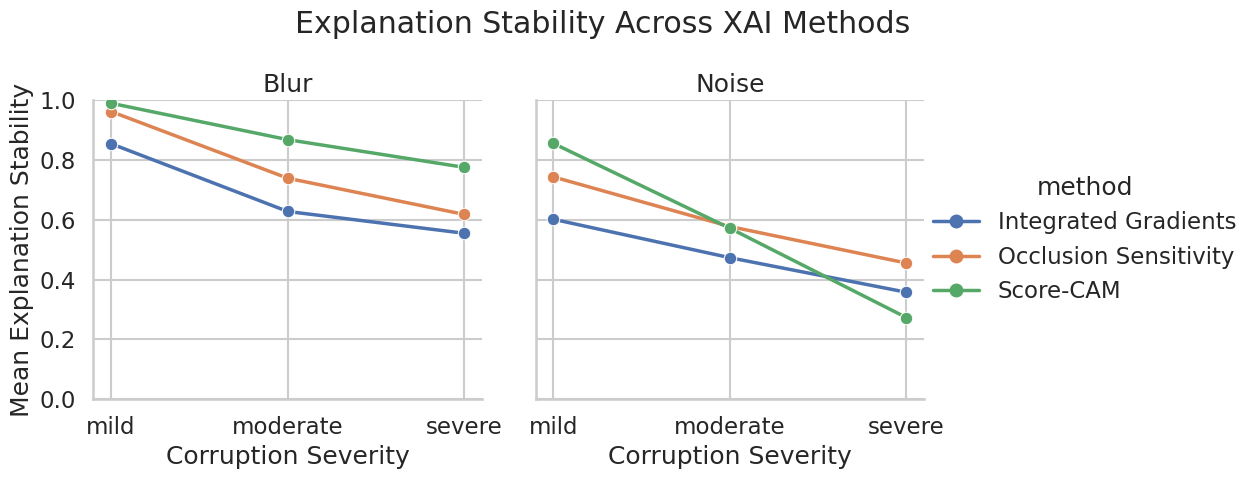

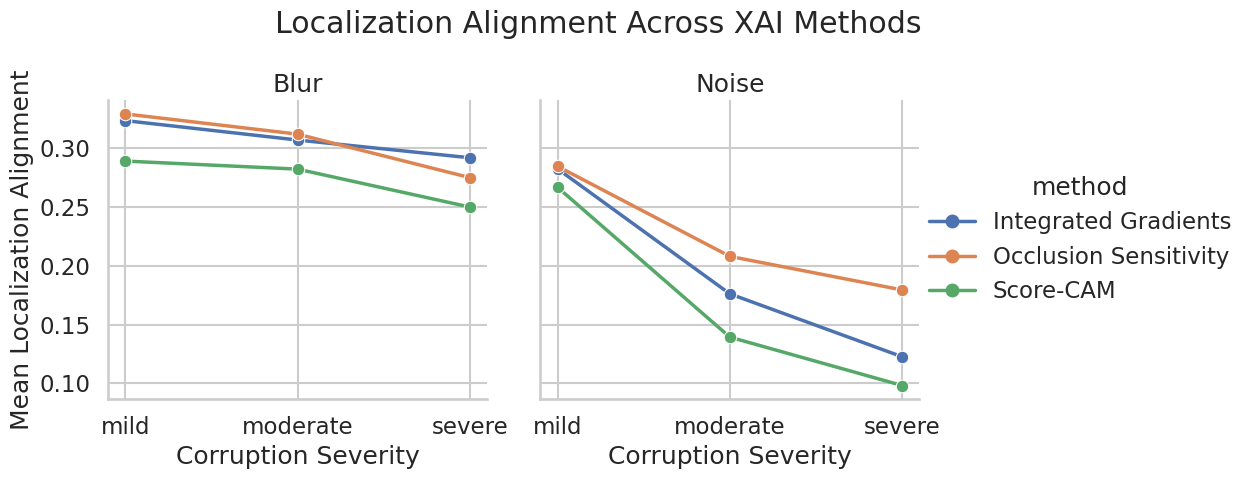

Both comparison figures saved successfully!


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme(style="whitegrid", context="talk")

# Exclude original images from the corruption comparison
plot_data = comparison_summary[
    comparison_summary["corruption"] != "Original"
].copy()

severity_order = ["mild", "moderate", "severe"]

plot_data["severity"] = pd.Categorical(
    plot_data["severity"],
    categories=severity_order,
    ordered=True
)

method_order = [
    "Integrated Gradients",
    "Occlusion Sensitivity",
    "Score-CAM"
]

# Figure 1: Explanation stability
g = sns.relplot(
    data=plot_data,
    x="severity",
    y="mean_stability",
    hue="method",
    hue_order=method_order,
    col="corruption",
    kind="line",
    marker="o",
    linewidth=2.5,
    height=4.5,
    aspect=1.1,
    facet_kws={"sharey": True}
)

g.set_axis_labels(
    "Corruption Severity",
    "Mean Explanation Stability"
)
g.set_titles("{col_name}")
g.set(ylim=(0, 1))
g.figure.suptitle(
    "Explanation Stability Across XAI Methods",
    y=1.08
)

g.savefig(
    EXPANDED_DIR / "xai_stability_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Figure 2: Localization alignment
g = sns.relplot(
    data=plot_data,
    x="severity",
    y="mean_alignment",
    hue="method",
    hue_order=method_order,
    col="corruption",
    kind="line",
    marker="o",
    linewidth=2.5,
    height=4.5,
    aspect=1.1,
    facet_kws={"sharey": True}
)

g.set_axis_labels(
    "Corruption Severity",
    "Mean Localization Alignment"
)
g.set_titles("{col_name}")
g.figure.suptitle(
    "Localization Alignment Across XAI Methods",
    y=1.08
)

g.savefig(
    EXPANDED_DIR / "xai_alignment_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Both comparison figures saved successfully!")

In [ ]:
import inspect

for name, obj in globals().copy().items():
    if callable(obj) and any(
        term in name.lower()
        for term in ["grad", "occlusion", "scorecam", "explanation"]
    ):
        print(name)

ScoreCAM
generate_scorecam_explanation


In [ ]:
import inspect

for name in [
    "IntegratedGradients",
    "Occlusion",
    "ig",
    "occlusion",
    "generate_scorecam_explanation",
    "prepare_corrupted_image",
    "calculate_alignment"
]:
    obj = globals().get(name)

    if obj is None:
        print(f"{name}: NOT LOADED")
    else:
        print(f"{name}: LOADED")
        if inspect.isfunction(obj):
            print("  Arguments:", inspect.signature(obj))

IntegratedGradients: NOT LOADED
Occlusion: NOT LOADED
ig: NOT LOADED
occlusion: NOT LOADED
generate_scorecam_explanation: LOADED
  Arguments: (image, target_class)
prepare_corrupted_image: LOADED
  Arguments: (image)
calculate_alignment: LOADED
  Arguments: (cam_map, boxes)


In [ ]:
for name in [
    "generate_ig_explanation",
    "generate_occlusion_map",
    "generate_scorecam_explanation"
]:
    print(name, callable(globals().get(name)))

generate_ig_explanation True
generate_occlusion_map True
generate_scorecam_explanation True


Image: 1.2.276.0.7230010.3.1.4.8323329.1684.1517874292.301663
True class: 1
Predicted class: 1
Pneumonia probability: 0.9332
Radiologist boxes: 2


100%|██████████| 512/512 [00:19<00:00, 26.87it/s]


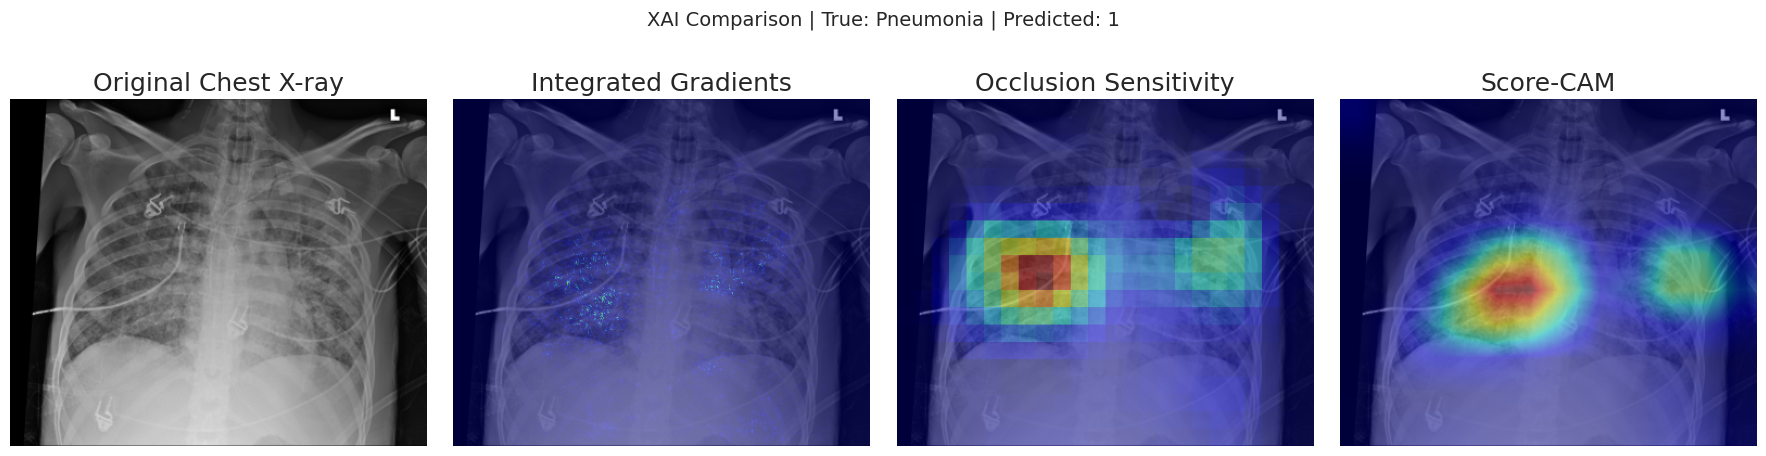

Figure saved to: /content/drive/MyDrive/XAI_project_Expo_1_folder/Results/ExpandedEvaluation/xai_single_image_comparison.png


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Select a pneumonia-positive image with annotations
row = expanded_sample[
    expanded_sample["target"] == 1
].iloc[0]

uid = str(row["sop_uid"])
image = resize_image(load_dicom(row["image_path"]))
boxes = opacity_lookup.get(uid, [])

# Use the model's original predicted class as the XAI target
probability, predicted_class = get_model_prediction(image)

print("Image:", uid)
print("True class:", int(row["target"]))
print("Predicted class:", predicted_class)
print("Pneumonia probability:", round(probability, 4))
print("Radiologist boxes:", len(boxes))

# Generate explanations for this ONE image
ig_result = generate_ig_explanation(
    image,
    target_class=predicted_class
)
ig_map = ig_result["magnitude_map"]

os_map, _ = generate_occlusion_map(
    image=image,
    model=model,
    device=device,
    target_class=predicted_class,
    window_size=32,
    stride=16,
    batch_size=32
)
os_map = np.abs(np.asarray(os_map))

scorecam_map = generate_scorecam_explanation(
    image,
    target_class=predicted_class
)

# Normalize heatmaps for visualization only
def normalize_heatmap(heatmap):
    heatmap = np.asarray(heatmap, dtype=float)
    heatmap = np.squeeze(heatmap)
    heatmap = heatmap - heatmap.min()
    return heatmap / (heatmap.max() + 1e-8)

# Plot the original and three explanations
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original Chest X-ray")

heatmaps = [
    ("Integrated Gradients", ig_map),
    ("Occlusion Sensitivity", os_map),
    ("Score-CAM", scorecam_map)
]

for ax, (title, heatmap) in zip(axes[1:], heatmaps):
    ax.imshow(image, cmap="gray")
    ax.imshow(
        normalize_heatmap(heatmap),
        cmap="jet",
        alpha=0.45,
        vmin=0,
        vmax=1
    )
    ax.set_title(title)

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"XAI Comparison | True: Pneumonia | Predicted: {predicted_class}",
    fontsize=14
)
plt.tight_layout()

output_file = EXPANDED_DIR / "xai_single_image_comparison.png"
plt.savefig(output_file, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved to:", output_file)

In [ ]:
print("Image UID:", uid)
print("Number of bounding boxes:", len(boxes))
print("Bounding box data:")
print(boxes[:5])

Image UID: 1.2.276.0.7230010.3.1.4.8323329.1684.1517874292.301663
Number of bounding boxes: 2
Bounding box data:
[{'id': 'A_enl570', 'createdAt': '2018-07-03T22:59:39.879Z', 'createdById': 'U_1z6', 'updatedAt': '2018-07-03T22:59:39.884Z', 'updatedById': 'U_1z6', 'machineLearningModelId': None, 'StudyInstanceUID': '1.2.276.0.7230010.3.1.2.8323329.1684.1517874292.301662', 'SeriesInstanceUID': '1.2.276.0.7230010.3.1.3.8323329.1684.1517874292.301661', 'SOPInstanceUID': '1.2.276.0.7230010.3.1.4.8323329.1684.1517874292.301663', 'labelId': 'L_v8n', 'annotationNumber': 1, 'height': 1024, 'width': 1024, 'data': {'x': 265, 'y': 368, 'width': 172, 'height': 277}, 'note': None, 'radlexTagIds': [], 'reviewsPositiveCount': 0, 'reviewsNegativeCount': 0}, {'id': 'A_x0d3n8', 'createdAt': '2018-07-03T23:00:48.608Z', 'createdById': 'U_1z6', 'updatedAt': '2018-07-03T23:00:48.614Z', 'updatedById': 'U_1z6', 'machineLearningModelId': None, 'StudyInstanceUID': '1.2.276.0.7230010.3.1.2.8323329.1684.1517874292.

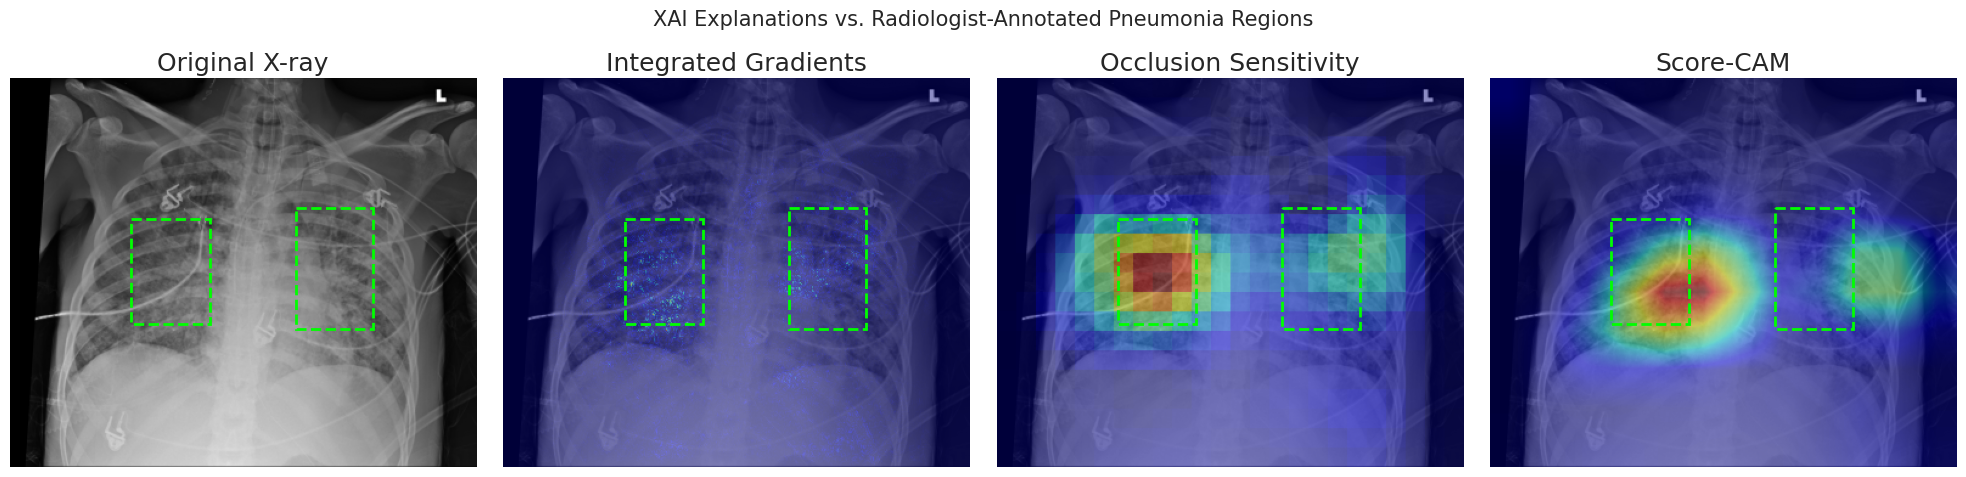

Annotated comparison saved to: /content/drive/MyDrive/XAI_project_Expo_1_folder/Results/ExpandedEvaluation/xai_comparison_with_annotations.png


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Get image dimensions
image_height, image_width = image.shape[:2]

# Prepare the three existing heatmaps
heatmaps = [
    ("Integrated Gradients", ig_map),
    ("Occlusion Sensitivity", os_map),
    ("Score-CAM", scorecam_map)
]

def add_radiologist_boxes(ax, boxes, image_width, image_height):
    for annotation in boxes:
        box = annotation["data"]

        # Scale coordinates from original annotation dimensions
        scale_x = image_width / annotation["width"]
        scale_y = image_height / annotation["height"]

        rect = Rectangle(
            (
                box["x"] * scale_x,
                box["y"] * scale_y
            ),
            box["width"] * scale_x,
            box["height"] * scale_y,
            linewidth=2,
            edgecolor="lime",
            facecolor="none",
            linestyle="--"
        )

        ax.add_patch(rect)

# Create figure
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

# Original X-ray
axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original X-ray")

# Three XAI explanations
for ax, (title, heatmap) in zip(axes[1:], heatmaps):
    ax.imshow(image, cmap="gray")

    ax.imshow(
        normalize_heatmap(heatmap),
        cmap="jet",
        alpha=0.45,
        vmin=0,
        vmax=1
    )

    ax.set_title(title)

# Add radiologist bounding boxes to every panel
for ax in axes:
    add_radiologist_boxes(
        ax,
        boxes,
        image_width,
        image_height
    )
    ax.axis("off")

fig.suptitle(
    "XAI Explanations vs. Radiologist-Annotated Pneumonia Regions",
    fontsize=15
)

plt.tight_layout()

# Save figure
output_path = (
    EXPANDED_DIR / "xai_comparison_with_annotations.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Annotated comparison saved to:", output_path)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Reuse the image, annotations, and model prediction
original_image = image.copy()
original_target = predicted_class

# Use the same corruption settings as the full experiment
conditions = [
    ("Original", None, None),
    ("Blur", "severe", 3.0),
    ("Noise", "severe", 0.10)
]

def add_boxes(ax, annotations, image_shape):
    h, w = image_shape[:2]

    for annotation in annotations:
        b = annotation["data"]

        sx = w / annotation["width"]
        sy = h / annotation["height"]

        rect = Rectangle(
            (b["x"] * sx, b["y"] * sy),
            b["width"] * sx,
            b["height"] * sy,
            linewidth=1.8,
            edgecolor="lime",
            facecolor="none",
            linestyle="--"
        )
        ax.add_patch(rect)

fig, axes = plt.subplots(3, 4, figsize=(18, 13))

column_titles = [
    "Input X-ray",
    "Integrated Gradients",
    "Occlusion Sensitivity",
    "Score-CAM"
]

for row_idx, (corruption, severity, sigma) in enumerate(conditions):

    print(f"Processing {corruption} ({severity})...", flush=True)

    corrupted = create_corrupted_image(
        original_image, corruption, severity, sigma
    )

    # Same target class for all explanations
    ig_result = generate_ig_explanation(
        corrupted, target_class=original_target
    )
    ig_heatmap = ig_result["magnitude_map"]

    os_heatmap, _ = generate_occlusion_map(
        image=corrupted,
        model=model,
        device=device,
        target_class=original_target,
        window_size=32,
        stride=16,
        batch_size=32
    )
    os_heatmap = np.abs(np.asarray(os_heatmap))

    scorecam_heatmap = generate_scorecam_explanation(
        corrupted, target_class=original_target
    )

    # Plot input
    axes[row_idx, 0].imshow(corrupted, cmap="gray")

    # Plot explanations
    for col_idx, heatmap in enumerate(
        [ig_heatmap, os_heatmap, scorecam_heatmap], start=1
    ):
        ax = axes[row_idx, col_idx]
        ax.imshow(corrupted, cmap="gray")
        ax.imshow(
            normalize_heatmap(heatmap),
            cmap="jet",
            alpha=0.45,
            vmin=0,
            vmax=1
        )

    # Add bounding boxes
    for col_idx in range(4):
        ax = axes[row_idx, col_idx]
        add_boxes(ax, boxes, corrupted.shape)
        ax.axis("off")

        if row_idx == 0:
            ax.set_title(column_titles[col_idx], fontsize=13)

    axes[row_idx, 0].set_ylabel(
        "Original" if corruption == "Original" else f"Severe {corruption}",
        fontsize=13
    )

    print(f"Finished {corruption}", flush=True)

fig.suptitle(
    "XAI Explanation Robustness Under Blur and Noise",
    fontsize=17,
    y=1.01
)

plt.tight_layout()

output_path = EXPANDED_DIR / "xai_robustness_visual_comparison.png"

plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved to:", output_path)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
import pandas as pd
import numpy as np

# Use only original images from one method to avoid duplicates
original_predictions = combined_xai[
    (combined_xai["method"] == "Integrated Gradients") &
    (combined_xai["corruption"] == "Original")
].copy()

# Assign confusion matrix categories
conditions = [
    (original_predictions["true_class"] == 1) &
    (original_predictions["original_predicted_class"] == 1),

    (original_predictions["true_class"] == 0) &
    (original_predictions["original_predicted_class"] == 0),

    (original_predictions["true_class"] == 0) &
    (original_predictions["original_predicted_class"] == 1),

    (original_predictions["true_class"] == 1) &
    (original_predictions["original_predicted_class"] == 0)
]

labels = [
    "True Positive",
    "True Negative",
    "False Positive",
    "False Negative"
]

original_predictions["prediction_category"] = np.select(
    conditions,
    labels,
    default="Unknown"
)

category_counts = (
    original_predictions["prediction_category"]
    .value_counts()
    .reindex(labels, fill_value=0)
)

print("Prediction categories among 300 images:")
print(category_counts)

print("\nTotal:", category_counts.sum())

Prediction categories among 300 images:
prediction_category
True Positive     128
True Negative     109
False Positive     41
False Negative     22
Name: count, dtype: int64

Total: 300


In [ ]:
import pandas as pd

analysis_data = combined_xai[
    combined_xai["corruption"] != "Original"
].copy()

analysis_data["prediction_group"] = analysis_data[
    "original_correct"
].map({
    1: "Correct",
    0: "Incorrect"
})

stability_by_correctness = (
    analysis_data
    .groupby(
        ["method", "corruption", "severity", "prediction_group"],
        as_index=False
    )
    .agg(
        mean_stability=("explanation_similarity", "mean"),
        sd_stability=("explanation_similarity", "std"),
        n_images=("sop_uid", "nunique")
    )
)

display(stability_by_correctness.round(4))

,method,corruption,severity,prediction_group,mean_stability,sd_stability,n_images
0,Integrated Gradients,Blur,mild,Correct,0.8574,0.0322,237
1,Integrated Gradients,Blur,mild,Incorrect,0.8450,0.0342,63
2,Integrated Gradients,Blur,moderate,Correct,0.6360,0.0917,237
3,Integrated Gradients,Blur,moderate,Incorrect,0.5980,0.1018,63
4,Integrated Gradients,Blur,severe,Correct,0.5622,0.1144,237
5,Integrated Gradients,Blur,severe,Incorrect,0.5282,0.1148,63
6,Integrated Gradients,Noise,mild,Correct,0.6099,0.0996,237
7,Integrated Gradients,Noise,mild,Incorrect,0.5721,0.1133,63
8,Integrated Gradients,Noise,moderate,Correct,0.4806,0.1240,237
9,Integrated Gradients,Noise,moderate,Incorrect,0.4460,0.1404,63


In [ ]:
import numpy as np
import pandas as pd

category_data = combined_xai[
    combined_xai["corruption"] != "Original"
].copy()

# Assign categories based on original predictions
category_data["prediction_category"] = np.select(
    [
        (category_data["true_class"] == 1) &
        (category_data["original_predicted_class"] == 1),

        (category_data["true_class"] == 1) &
        (category_data["original_predicted_class"] == 0),

        (category_data["true_class"] == 0) &
        (category_data["original_predicted_class"] == 0),

        (category_data["true_class"] == 0) &
        (category_data["original_predicted_class"] == 1)
    ],
    [
        "TP",
        "FN",
        "TN",
        "FP"
    ],
    default="Unknown"
)

# Summarize explanation stability
category_summary = (
    category_data
    .groupby(
        ["method", "corruption", "severity", "prediction_category"],
        as_index=False
    )
    .agg(
        mean_stability=("explanation_similarity", "mean"),
        sd_stability=("explanation_similarity", "std"),
        n_images=("sop_uid", "nunique")
    )
)

# Focus on severe corruption first
severe_summary = category_summary[
    category_summary["severity"] == "severe"
].copy()

display(
    severe_summary.sort_values(
        ["method", "corruption", "prediction_category"]
    ).round(4)
)

,method,corruption,severity,prediction_category,mean_stability,sd_stability,n_images
8,Integrated Gradients,Blur,severe,FN,0.5393,0.1177,22
9,Integrated Gradients,Blur,severe,FP,0.5223,0.1142,41
10,Integrated Gradients,Blur,severe,TN,0.5280,0.1089,109
11,Integrated Gradients,Blur,severe,TP,0.5913,0.1112,128
20,Integrated Gradients,Noise,severe,FN,0.3734,0.1415,22
21,Integrated Gradients,Noise,severe,FP,0.3121,0.1394,41
22,Integrated Gradients,Noise,severe,TN,0.3486,0.1189,109
23,Integrated Gradients,Noise,severe,TP,0.3770,0.1378,128
32,Occlusion Sensitivity,Blur,severe,FN,0.4593,0.1491,22
33,Occlusion Sensitivity,Blur,severe,FP,0.6493,0.1419,41



### 7.1 Paired Bootstrap Comparison

The three explanation methods are evaluated on the same images, enabling paired comparisons of their stability scores.

For each corruption type and severity, the analysis matches images by `sop_uid` and calculates differences in explanation stability between methods.

The bootstrap resamples these paired image-level differences 5,000 times to construct percentile confidence intervals for the mean differences.

Because the bootstrap is performed separately within each corruption condition, the paired observations are resampled at the image level within that condition.

These intervals quantify sampling uncertainty for the evaluated images under the chosen resampling assumptions. They do not establish clinical superiority or external generalizability.


In [ ]:
import numpy as np
import pandas as pd
from itertools import combinations

rng = np.random.default_rng(42)
n_bootstrap = 5000

# Exclude original images: stability is 1 by definition
bootstrap_data = combined_xai[
    combined_xai["corruption"] != "Original"
].copy()

methods = [
    "Integrated Gradients",
    "Occlusion Sensitivity",
    "Score-CAM"
]

results = []

for (corruption, severity), group in bootstrap_data.groupby(
    ["corruption", "severity"]
):

    # Match explanations from the same images
    paired = group.pivot_table(
        index="sop_uid",
        columns="method",
        values="explanation_similarity",
        aggfunc="first"
    )

    for method_a, method_b in combinations(methods, 2):

        matched = paired[
            [method_a, method_b]
        ].dropna()

        # Image-level paired differences
        differences = (
            matched[method_a] - matched[method_b]
        ).to_numpy()

        n = len(differences)

        if n < 2:
            continue

        observed_difference = differences.mean()

        # Resample paired image differences
        bootstrap_means = np.empty(n_bootstrap)

        for i in range(n_bootstrap):
            sample = rng.choice(
                differences,
                size=n,
                replace=True
            )

            bootstrap_means[i] = sample.mean()

        ci_lower, ci_upper = np.percentile(
            bootstrap_means,
            [2.5, 97.5]
        )

        results.append({
            "corruption": corruption,
            "severity": severity,
            "method_a": method_a,
            "method_b": method_b,
            "n_images": n,
            "mean_difference": observed_difference,
            "ci_lower": ci_lower,
            "ci_upper": ci_upper,
            "ci_excludes_zero": (
                ci_lower > 0 or ci_upper < 0
            )
        })

paired_bootstrap_results = pd.DataFrame(results)

display(
    paired_bootstrap_results.round(4)
)

paired_bootstrap_results.to_csv(
    EXPANDED_DIR / "xai_paired_bootstrap_results.csv",
    index=False
)

print("Paired bootstrap results saved successfully.")

,corruption,severity,method_a,method_b,n_images,mean_difference,ci_lower,ci_upper,ci_excludes_zero
0,Blur,mild,Integrated Gradients,Occlusion Sensitivity,300,-0.1078,-0.1127,-0.1028,True
1,Blur,mild,Integrated Gradients,Score-CAM,300,-0.1355,-0.1389,-0.1319,True
2,Blur,mild,Occlusion Sensitivity,Score-CAM,300,-0.0277,-0.0316,-0.0241,True
3,Blur,moderate,Integrated Gradients,Occlusion Sensitivity,300,-0.1113,-0.1258,-0.0966,True
4,Blur,moderate,Integrated Gradients,Score-CAM,300,-0.2404,-0.2498,-0.2309,True
5,Blur,moderate,Occlusion Sensitivity,Score-CAM,300,-0.1291,-0.1410,-0.1171,True
6,Blur,severe,Integrated Gradients,Occlusion Sensitivity,300,-0.0630,-0.0818,-0.0437,True
7,Blur,severe,Integrated Gradients,Score-CAM,300,-0.2206,-0.2326,-0.2093,True
8,Blur,severe,Occlusion Sensitivity,Score-CAM,300,-0.1576,-0.1741,-0.1416,True
9,Noise,mild,Integrated Gradients,Occlusion Sensitivity,300,-0.1419,-0.1554,-0.1284,True


Paired bootstrap results saved successfully.


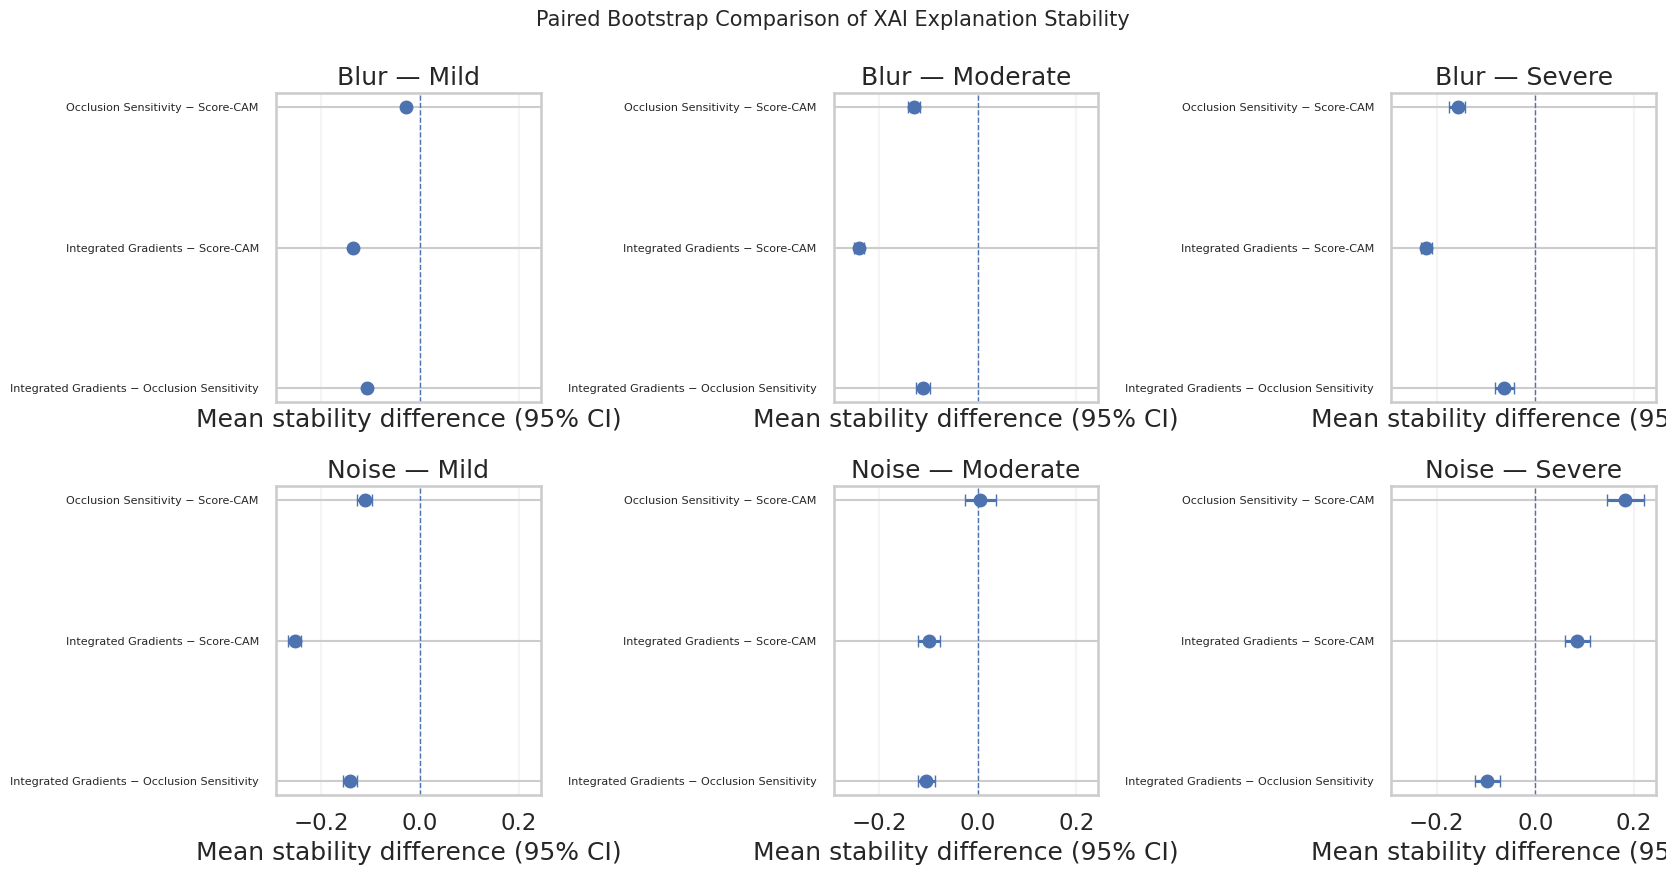

In [ ]:
import matplotlib.pyplot as plt

plot_data = paired_bootstrap_results.copy()

plot_data["comparison"] = (
    plot_data["method_a"] + " − " + plot_data["method_b"]
)

severity_order = ["mild", "moderate", "severe"]

fig, axes = plt.subplots(
    2, 3,
    figsize=(17, 9),
    sharex=True
)

for i, corruption in enumerate(["Blur", "Noise"]):
    for j, severity in enumerate(severity_order):

        ax = axes[i, j]

        subset = plot_data[
            (plot_data["corruption"] == corruption) &
            (plot_data["severity"] == severity)
        ].reset_index(drop=True)

        y = np.arange(len(subset))

        ax.errorbar(
            subset["mean_difference"],
            y,
            xerr=[
                subset["mean_difference"] - subset["ci_lower"],
                subset["ci_upper"] - subset["mean_difference"]
            ],
            fmt="o",
            capsize=4
        )

        ax.axvline(0, linestyle="--", linewidth=1)

        ax.set_yticks(y)
        ax.set_yticklabels(subset["comparison"], fontsize=8)
        ax.set_title(f"{corruption} — {severity.capitalize()}")
        ax.set_xlabel("Mean stability difference (95% CI)")
        ax.grid(axis="x", alpha=0.2)

plt.suptitle(
    "Paired Bootstrap Comparison of XAI Explanation Stability",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    EXPANDED_DIR / "xai_paired_bootstrap_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/XAI_project_Expo_1_folder")
EXPANDED_DIR = PROJECT_DIR / "Results" / "ExpandedEvaluation"

df = pd.read_csv(EXPANDED_DIR / "combined_xai_results.csv")

print(df.shape)
display(df.head())

(6300, 15)


,sop_uid,true_class,original_predicted_class,original_correct,corrupted_predicted_class,prediction_changed,corruption,severity,sigma,opacity_probability,explanation_similarity,localization_alignment,n_boxes,convergence_delta,method
0,1.2.276.0.7230010.3.1.4.8323329.10261.15178743...,1,1,1,1,0,Original,original,NaN,0.557537,1.000000,0.124000,2,0.005070,Integrated Gradients
1,1.2.276.0.7230010.3.1.4.8323329.10261.15178743...,1,1,1,1,0,Blur,mild,0.50,0.545375,0.876866,0.114374,2,0.001359,Integrated Gradients
2,1.2.276.0.7230010.3.1.4.8323329.10261.15178743...,1,1,1,1,0,Blur,moderate,1.50,0.535043,0.704839,0.103902,2,-0.001010,Integrated Gradients
3,1.2.276.0.7230010.3.1.4.8323329.10261.15178743...,1,1,1,1,0,Blur,severe,3.00,0.569804,0.667035,0.137434,2,-0.006207,Integrated Gradients
4,1.2.276.0.7230010.3.1.4.8323329.10261.15178743...,1,1,1,1,0,Noise,mild,0.02,0.545769,0.695091,0.145971,2,-0.005487,Integrated Gradients


In [ ]:
positive_df = df[
    (df["true_class"] == 1) &
    (df["n_boxes"] > 0)
]

print("Unique annotated positive images:",
      positive_df["sop_uid"].nunique())

Unique annotated positive images: 150



## 8. Relationship Between Explanation Stability and Localization

This section examines whether explanations with higher stability also tend to exhibit higher localization alignment.

For each explanation method and corruption condition, Spearman correlation is calculated between explanation stability and localization alignment across annotated positive images.

A positive association indicates that more stable explanations tend to have higher localization alignment within that condition.

However, the association alone does not establish whether localization alignment was preserved relative to the original image.

The next section therefore calculates the change in alignment for each image directly.


In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import spearmanr

# Filter to annotated positive images and corrupted conditions
analysis = df.loc[
    (df["true_class"] == 1) &
    (df["n_boxes"] > 0) &
    (df["corruption"] != "Original") &
    df["explanation_similarity"].notna() &
    df["localization_alignment"].notna()
].copy()

print("Analysis dataset:", analysis.shape)

results = []

for (method, corruption, severity), group in analysis.groupby(
    ["method", "corruption", "severity"]
):
    assert group["sop_uid"].is_unique

    rho, p_value = spearmanr(
        group["explanation_similarity"],
        group["localization_alignment"]
    )

    results.append({
        "Method": method,
        "Corruption": corruption,
        "Severity": severity,
        "N": len(group),
        "Spearman_Rho": rho,
        "P_Value": p_value
    })

correlation_results = pd.DataFrame(results)

display(
    correlation_results.sort_values(
        ["Corruption", "Severity", "Method"]
    ).round(4)
)

correlation_results.to_csv(
    EXPANDED_DIR / "stability_localization_associations.csv",
    index=False
)

print("Correlation results saved successfully!")

Analysis dataset: (2700, 15)


,Method,Corruption,Severity,N,Spearman_Rho,P_Value
0,Integrated Gradients,Blur,mild,150,0.3172,0.0001
6,Occlusion Sensitivity,Blur,mild,150,0.2728,0.0007
12,Score-CAM,Blur,mild,150,0.3732,0.0000
1,Integrated Gradients,Blur,moderate,150,0.3311,0.0000
7,Occlusion Sensitivity,Blur,moderate,150,0.4507,0.0000
13,Score-CAM,Blur,moderate,150,0.4507,0.0000
2,Integrated Gradients,Blur,severe,150,0.3845,0.0000
8,Occlusion Sensitivity,Blur,severe,150,0.4582,0.0000
14,Score-CAM,Blur,severe,150,0.3698,0.0000
3,Integrated Gradients,Noise,mild,150,0.3186,0.0001


Correlation results saved successfully!



## 9. Stability–Localization Disagreement Audit

The primary audit investigates whether high explanation stability can coexist with a substantial reduction in localization alignment.

### Localization Change

For each annotated positive image, method, and corruption condition:

$$
\Delta L = L_{\text{corrupted}} - L_{\text{original}}
$$

A negative value indicates reduced localization alignment after corruption.

### Primary Disagreement Criterion

An evaluation is flagged when:

$$
S \geq 0.80
\quad \text{and} \quad
\Delta L \leq -0.05
$$

The thresholds are exploratory operational choices, not clinically validated cutoffs.

### Evaluation Scope

The audit contains 150 annotated positive images, three explanation methods, and six corruption conditions, giving 2,700 repeated evaluations.

Because the same images are evaluated under multiple methods and corruptions, these evaluations are not statistically independent.

A flagged case demonstrates disagreement between the two selected metrics, not necessarily a clinically incorrect explanation.


In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import spearmanr

# Get original localization alignment for each positive image
original = df.loc[
    (df["corruption"] == "Original") &
    (df["true_class"] == 1) &
    (df["n_boxes"] > 0),
    ["sop_uid", "method", "localization_alignment"]
].rename(columns={
    "localization_alignment": "original_alignment"
})

# Get corrupted positive images
corrupted = df.loc[
    (df["corruption"] != "Original") &
    (df["true_class"] == 1) &
    (df["n_boxes"] > 0)
].copy()

# Match each corrupted image to its original
change_df = corrupted.merge(
    original,
    on=["sop_uid", "method"],
    how="left",
    validate="many_to_one"
)

# Calculate change in localization
change_df["alignment_change"] = (
    change_df["localization_alignment"]
    - change_df["original_alignment"]
)

print("Dataset shape:", change_df.shape)
print("Unique images:", change_df["sop_uid"].nunique())
print("Missing original alignments:",
      change_df["original_alignment"].isna().sum())

display(change_df[
    ["method", "corruption", "severity",
     "explanation_similarity", "original_alignment",
     "localization_alignment", "alignment_change"]
].head())

Dataset shape: (2700, 17)
Unique images: 150
Missing original alignments: 0


,method,corruption,severity,explanation_similarity,original_alignment,localization_alignment,alignment_change
0,Integrated Gradients,Blur,mild,0.876866,0.124,0.114374,-0.009625
1,Integrated Gradients,Blur,moderate,0.704839,0.124,0.103902,-0.020098
2,Integrated Gradients,Blur,severe,0.667035,0.124,0.137434,0.013435
3,Integrated Gradients,Noise,mild,0.695091,0.124,0.145971,0.021971
4,Integrated Gradients,Noise,moderate,0.569649,0.124,0.057655,-0.066344



### 9.1 Localization Change Across Corruption Conditions

This section summarizes how localization alignment changes relative to each image's original explanation.

For each method and corruption condition, the analysis reports:

- Mean change in localization alignment.
- Percentage of evaluations with decreased localization alignment.
- Spearman association between explanation stability and localization change.

A negative mean alignment change indicates that attribution magnitude becomes less concentrated within the annotated opacity regions on average.

This analysis provides additional context for the disagreement audit. An explanation may experience substantial localization deterioration without meeting the high-stability requirement.

The reported associations are exploratory and should not be interpreted as evidence of causal relationships.


In [ ]:
results = []

for (method, corruption, severity), group in change_df.groupby(
    ["method", "corruption", "severity"]
):
    valid = group.dropna(
        subset=["explanation_similarity", "alignment_change"]
    )

    assert valid["sop_uid"].is_unique

    if (
        len(valid) >= 3
        and valid["explanation_similarity"].nunique() > 1
        and valid["alignment_change"].nunique() > 1
    ):
        rho, p_value = spearmanr(
            valid["explanation_similarity"],
            valid["alignment_change"]
        )
    else:
        rho, p_value = np.nan, np.nan

    results.append({
        "Method": method,
        "Corruption": corruption,
        "Severity": severity,
        "N": len(valid),
        "Mean_Alignment_Change": valid["alignment_change"].mean(),
        "Pct_Alignment_Decreased": (
            valid["alignment_change"] < 0
        ).mean() * 100,
        "Spearman_Rho": rho,
        "P_Value": p_value
    })

change_results = pd.DataFrame(results)

display(
    change_results.sort_values(
        ["Corruption", "Severity", "Method"]
    ).round(4)
)

change_results.to_csv(
    EXPANDED_DIR / "stability_localization_change_results.csv",
    index=False
)

change_df.to_csv(
    EXPANDED_DIR / "image_level_localization_changes.csv",
    index=False
)

print("Results saved successfully!")

,Method,Corruption,Severity,N,Mean_Alignment_Change,Pct_Alignment_Decreased,Spearman_Rho,P_Value
0,Integrated Gradients,Blur,mild,150,-0.0065,69.3333,-0.1684,0.0394
6,Occlusion Sensitivity,Blur,mild,150,0.0024,46.6667,-0.2075,0.0108
12,Score-CAM,Blur,mild,150,0.0033,38.6667,-0.1802,0.0273
1,Integrated Gradients,Blur,moderate,150,-0.0231,68.6667,-0.0141,0.8639
7,Occlusion Sensitivity,Blur,moderate,150,-0.0148,64.0000,-0.1238,0.1312
13,Score-CAM,Blur,moderate,150,-0.0036,57.3333,-0.0977,0.2342
2,Integrated Gradients,Blur,severe,150,-0.0381,70.0000,0.0884,0.2822
8,Occlusion Sensitivity,Blur,severe,150,-0.0518,82.6667,-0.0674,0.4127
14,Score-CAM,Blur,severe,150,-0.0359,69.3333,0.0675,0.4117
3,Integrated Gradients,Noise,mild,150,-0.0476,78.6667,0.1575,0.0542


Results saved successfully!


In [ ]:
import pandas as pd
import numpy as np

# Primary audit thresholds
STABILITY_THRESHOLD = 0.80
LOSS_THRESHOLD = 0.05

audit_df = change_df.copy()

# Identify high-stability explanations
audit_df["high_stability"] = (
    audit_df["explanation_similarity"] >= STABILITY_THRESHOLD
)

# Identify meaningful localization decreases
audit_df["localization_loss"] = (
    audit_df["alignment_change"] <= -LOSS_THRESHOLD
)

# Flag disagreements
audit_df["disagreement"] = (
    audit_df["high_stability"] &
    audit_df["localization_loss"]
)

# Summarize by XAI method and corruption condition
audit_summary = (
    audit_df.groupby(["method", "corruption", "severity"])
    .agg(
        N=("sop_uid", "size"),
        High_Stability=("high_stability", "sum"),
        Localization_Loss=("localization_loss", "sum"),
        Disagreements=("disagreement", "sum")
    )
    .reset_index()
)

audit_summary["Disagreement_Rate_Pct"] = (
    audit_summary["Disagreements"] /
    audit_summary["N"] * 100
)

display(
    audit_summary.sort_values(
        ["corruption", "severity", "method"]
    ).round(2)
)

audit_df.to_csv(
    EXPANDED_DIR / "stability_localization_audit.csv",
    index=False
)

audit_summary.to_csv(
    EXPANDED_DIR / "stability_localization_audit_summary.csv",
    index=False
)

print("Disagreement audit completed and saved!")

,method,corruption,severity,N,High_Stability,Localization_Loss,Disagreements,Disagreement_Rate_Pct
0,Integrated Gradients,Blur,mild,150,148,1,1,0.67
6,Occlusion Sensitivity,Blur,mild,150,150,0,0,0.00
12,Score-CAM,Blur,mild,150,150,0,0,0.00
1,Integrated Gradients,Blur,moderate,150,8,41,1,0.67
7,Occlusion Sensitivity,Blur,moderate,150,92,24,11,7.33
13,Score-CAM,Blur,moderate,150,136,17,16,10.67
2,Integrated Gradients,Blur,severe,150,7,60,4,2.67
8,Occlusion Sensitivity,Blur,severe,150,63,75,33,22.00
14,Score-CAM,Blur,severe,150,93,50,27,18.00
3,Integrated Gradients,Noise,mild,150,7,63,4,2.67


Disagreement audit completed and saved!



### 9.2 Threshold Sensitivity

This section tests whether the observed disagreement frequency depends strongly on the selected thresholds.

Stability thresholds of 0.70, 0.80, and 0.90 are combined with localization-loss thresholds of 0.03, 0.05, and 0.10.

The primary criterion is stability ≥ 0.80 and localization loss ≥ 0.05.

The analysis reports the percentage of evaluations flagged under each threshold combination.

A lower flagged rate under a stricter stability threshold does not necessarily indicate less localization damage. Explanations that become highly unstable may fail the high-stability requirement even when localization deteriorates substantially.


In [ ]:
sensitivity_results = []

for stability_threshold in [0.70, 0.80, 0.90]:
    for loss_threshold in [0.03, 0.05, 0.10]:

        flagged = (
            (audit_df["explanation_similarity"] >= stability_threshold)
            &
            (audit_df["alignment_change"] <= -loss_threshold)
        )

        sensitivity_results.append({
            "Stability_Threshold": stability_threshold,
            "Loss_Threshold": loss_threshold,
            "Flagged_Count": int(flagged.sum()),
            "Flagged_Rate_Pct": 100 * flagged.mean()
        })

sensitivity_df = pd.DataFrame(sensitivity_results)

display(sensitivity_df.round(2))

sensitivity_df.to_csv(
    EXPANDED_DIR / "audit_threshold_sensitivity.csv",
    index=False
)

,Stability_Threshold,Loss_Threshold,Flagged_Count,Flagged_Rate_Pct
0,0.7,0.03,429,15.89
1,0.7,0.05,322,11.93
2,0.7,0.10,161,5.96
3,0.8,0.03,257,9.52
4,0.8,0.05,171,6.33
5,0.8,0.10,60,2.22
6,0.9,0.03,73,2.70
7,0.9,0.05,39,1.44
8,0.9,0.10,5,0.19


In [ ]:
examples = (
    audit_df.loc[audit_df["disagreement"]]
    .sort_values(
        ["explanation_similarity", "alignment_change"],
        ascending=[False, True]
    )
    [
        [
            "sop_uid",
            "method",
            "corruption",
            "severity",
            "explanation_similarity",
            "original_alignment",
            "localization_alignment",
            "alignment_change",
            "prediction_changed"
        ]
    ]
    .head(15)
)

display(examples)

,sop_uid,method,corruption,severity,explanation_similarity,original_alignment,localization_alignment,alignment_change,prediction_changed
2521,1.2.276.0.7230010.3.1.4.8323329.4425.151787430...,Score-CAM,Blur,moderate,0.974437,0.341170,0.290846,-0.050324,0
915,1.2.276.0.7230010.3.1.4.8323329.10662.15178743...,Occlusion Sensitivity,Noise,mild,0.960920,0.602607,0.541250,-0.061358,0
967,1.2.276.0.7230010.3.1.4.8323329.12539.15178743...,Occlusion Sensitivity,Blur,moderate,0.957885,0.476712,0.426357,-0.050355,0
1351,1.2.276.0.7230010.3.1.4.8323329.25037.15178744...,Occlusion Sensitivity,Blur,moderate,0.954368,0.469246,0.413707,-0.055539,0
981,1.2.276.0.7230010.3.1.4.8323329.12659.15178743...,Occlusion Sensitivity,Noise,mild,0.952325,0.740271,0.690116,-0.050155,0
1425,1.2.276.0.7230010.3.1.4.8323329.27461.15178744...,Occlusion Sensitivity,Noise,mild,0.950659,0.639810,0.569859,-0.069951,0
2179,1.2.276.0.7230010.3.1.4.8323329.22038.15178744...,Score-CAM,Blur,moderate,0.946537,0.498419,0.427774,-0.070644,0
2197,1.2.276.0.7230010.3.1.4.8323329.23367.15178744...,Score-CAM,Blur,moderate,0.944730,0.153419,0.100733,-0.052686,0
2323,1.2.276.0.7230010.3.1.4.8323329.27461.15178744...,Score-CAM,Blur,moderate,0.943887,0.675799,0.596650,-0.079149,0
1005,1.2.276.0.7230010.3.1.4.8323329.13195.15178743...,Occlusion Sensitivity,Noise,mild,0.940959,0.627254,0.543047,-0.084207,0


In [ ]:
print("Available columns:")
print(df.columns.tolist())

print("Audit dataframe available:", "audit_df" in globals())

if "audit_df" in globals():
    print(audit_df.columns.tolist())

Available columns:
['sop_uid', 'true_class', 'original_predicted_class', 'original_correct', 'corrupted_predicted_class', 'prediction_changed', 'corruption', 'severity', 'sigma', 'opacity_probability', 'explanation_similarity', 'localization_alignment', 'n_boxes', 'convergence_delta', 'method']
Audit dataframe available: True
['sop_uid', 'true_class', 'original_predicted_class', 'original_correct', 'corrupted_predicted_class', 'prediction_changed', 'corruption', 'severity', 'sigma', 'opacity_probability', 'explanation_similarity', 'localization_alignment', 'n_boxes', 'convergence_delta', 'method', 'original_alignment', 'alignment_change', 'high_stability', 'localization_loss', 'disagreement']



### 9.3 Prediction Consistency in Flagged Evaluations

This section examines whether the model's predicted class changes in cases identified by the stability–localization disagreement audit.

Original and corrupted predicted classes are compared for every flagged evaluation.

An unchanged predicted class does not imply that the model's confidence, internal decision process, or explanation remains unchanged.

This analysis helps establish whether explanation disagreement can occur even when the classifier continues assigning the same class.


In [ ]:
# Filter observations identified by the disagreement audit
flagged = audit_df.loc[audit_df["disagreement"] == True].copy()

# Compare original and corrupted predicted classes directly
flagged["prediction_unchanged"] = (
    flagged["original_predicted_class"]
    == flagged["corrupted_predicted_class"]
)

total = len(flagged)
unchanged = flagged["prediction_unchanged"].sum()
changed = total - unchanged

print(f"Total flagged evaluations: {total}")
print(f"Predictions unchanged: {unchanged}")
print(f"Predictions changed: {changed}")

if total > 0:
    print(f"Percentage unchanged: {100 * unchanged / total:.2f}%")
    print(f"Percentage changed: {100 * changed / total:.2f}%")

Total flagged evaluations: 171
Predictions unchanged: 169
Predictions changed: 2
Percentage unchanged: 98.83%
Percentage changed: 1.17%


In [ ]:
prediction_summary = (
    flagged.groupby("method")
    .agg(
        flagged_evaluations=("prediction_unchanged", "size"),
        predictions_unchanged=("prediction_unchanged", "sum")
    )
    .reset_index()
)

prediction_summary["predictions_changed"] = (
    prediction_summary["flagged_evaluations"]
    - prediction_summary["predictions_unchanged"]
)

prediction_summary["percent_unchanged"] = (
    100
    * prediction_summary["predictions_unchanged"]
    / prediction_summary["flagged_evaluations"]
)

display(prediction_summary.round(2))

# Save the results for your poster
prediction_summary.to_csv(
    EXPANDED_DIR / "audit_prediction_consistency.csv",
    index=False
)

,method,flagged_evaluations,predictions_unchanged,predictions_changed,percent_unchanged
0,Integrated Gradients,12,12,0,100.00
1,Occlusion Sensitivity,102,102,0,100.00
2,Score-CAM,57,55,2,96.49



## 10. Qualitative Case Study and Numerical Verification

This section selects a flagged evaluation in which the classifier's predicted class remains unchanged.

Candidate cases are ranked by the largest decrease in localization alignment, with explanation stability used as a secondary ranking criterion.

For the selected case, the notebook regenerates the original and corrupted attribution maps and visualizes their relationship to radiologist-annotated opacity bounding boxes.

The analysis then recalculates explanation stability, original alignment, corrupted alignment, and localization change.

These recalculated values are compared against the saved audit results using a tolerance of 0.001.

The selected example illustrates a documented disagreement, but it is not representative of all images or corruption conditions.


In [ ]:
import numpy as np
import pandas as pd

# Select valid flagged cases with unchanged predictions
candidates = audit_df.loc[
    audit_df["disagreement"]
    & (
        audit_df["original_predicted_class"]
        == audit_df["corrupted_predicted_class"]
    )
].copy()

# Prefer a substantial localization drop, while retaining high stability
candidates = candidates.sort_values(
    ["alignment_change", "explanation_similarity"],
    ascending=[True, False]
)

display(
    candidates[
        [
            "sop_uid",
            "method",
            "corruption",
            "severity",
            "sigma",
            "explanation_similarity",
            "original_alignment",
            "localization_alignment",
            "alignment_change",
        ]
    ].head(10).round(4)
)

# Select the first case
case = candidates.iloc[0]

print("Selected method:", case["method"])
print("Corruption:", case["corruption"])
print("Severity:", case["severity"])
print("Stability:", round(case["explanation_similarity"], 4))
print("Localization change:", round(case["alignment_change"], 4))

,sop_uid,method,corruption,severity,sigma,explanation_similarity,original_alignment,localization_alignment,alignment_change
2150,1.2.276.0.7230010.3.1.4.8323329.21634.15178744...,Score-CAM,Blur,severe,3.00,0.8105,0.4879,0.1610,-0.3269
1697,1.2.276.0.7230010.3.1.4.8323329.6220.151787432...,Occlusion Sensitivity,Noise,severe,0.10,0.8234,0.5208,0.2412,-0.2796
286,1.2.276.0.7230010.3.1.4.8323329.20046.15178744...,Integrated Gradients,Noise,moderate,0.05,0.8082,0.4403,0.1659,-0.2744
490,1.2.276.0.7230010.3.1.4.8323329.25852.15178744...,Integrated Gradients,Noise,moderate,0.05,0.8171,0.4876,0.2321,-0.2555
1696,1.2.276.0.7230010.3.1.4.8323329.6220.151787432...,Occlusion Sensitivity,Noise,moderate,0.05,0.8045,0.5208,0.2676,-0.2532
2420,1.2.276.0.7230010.3.1.4.8323329.29688.15178744...,Score-CAM,Blur,severe,3.00,0.8517,0.3449,0.1279,-0.2170
1775,1.2.276.0.7230010.3.1.4.8323329.9639.151787434...,Occlusion Sensitivity,Noise,severe,0.10,0.8342,0.5595,0.3529,-0.2066
1329,1.2.276.0.7230010.3.1.4.8323329.24665.15178744...,Occlusion Sensitivity,Noise,mild,0.02,0.8647,0.5903,0.3909,-0.1994
2229,1.2.276.0.7230010.3.1.4.8323329.24665.15178744...,Score-CAM,Noise,mild,0.02,0.8384,0.5254,0.3263,-0.1991
2659,1.2.276.0.7230010.3.1.4.8323329.8772.151787433...,Score-CAM,Blur,moderate,1.50,0.8321,0.4520,0.2540,-0.1980


Selected method: Score-CAM
Corruption: Blur
Severity: severe
Stability: 0.8105
Localization change: -0.3269


In [ ]:
required = [
    "generate_ig_explanation",
    "generate_occlusion_map",
    "generate_scorecam_explanation",
    "create_corrupted_image",
    "get_model_prediction",
    "calculate_alignment",
]

for name in required:
    print(f"{name}: {'Ready' if name in globals() else 'Missing'}")

generate_ig_explanation: Ready
generate_occlusion_map: Ready
generate_scorecam_explanation: Missing
create_corrupted_image: Missing
get_model_prediction: Missing
calculate_alignment: Ready


In [ ]:
required = [
    "expanded_sample",
    "audit_df",
    "case",
    "model",
    "device",
    "load_dicom",
    "resize_image",
    "prepare_corrupted_image",
    "opacity_lookup",
]

for name in required:
    print(f"{name}: {'Ready' if name in globals() else 'Missing'}")

expanded_sample: Ready
audit_df: Ready
case: Ready
model: Ready
device: Ready
load_dicom: Ready
resize_image: Ready
prepare_corrupted_image: Ready
opacity_lookup: Ready


In [ ]:
from pathlib import Path
import numpy as np

uid = str(case["sop_uid"])
method = case["method"]

sample_row = expanded_sample.loc[
    expanded_sample["sop_uid"].astype(str) == uid
].iloc[0]

original_image = resize_image(
    load_dicom(sample_row["image_path"])
)

corrupted_image = create_corrupted_image(
    original_image,
    case["corruption"],
    case["severity"],
    float(case["sigma"])
)

original_target = int(case["original_predicted_class"])

def generate_selected_explanation(image, method, target_class):

    if method == "Integrated Gradients":
        result = generate_ig_explanation(
            image,
            target_class=target_class
        )
        return result["magnitude_map"]

    elif method == "Occlusion Sensitivity":
        heatmap, _ = generate_occlusion_map(
            image=image,
            model=model,
            device=device,
            target_class=target_class,
            window_size=32,
            stride=16,
            batch_size=32
        )
        return np.abs(np.asarray(heatmap))

    elif method == "Score-CAM":
        return generate_scorecam_explanation(
            image,
            target_class=target_class
        )

    raise ValueError(f"Unknown method: {method}")

original_map = generate_selected_explanation(
    original_image, method, original_target
)

corrupted_map = generate_selected_explanation(
    corrupted_image, method, original_target
)

boxes = opacity_lookup.get(uid, [])

print("Explanations generated successfully.")
print("Radiologist annotations:", len(boxes))

100%|██████████| 512/512 [00:22<00:00, 22.35it/s]

Explanations generated successfully.
Radiologist annotations: 1


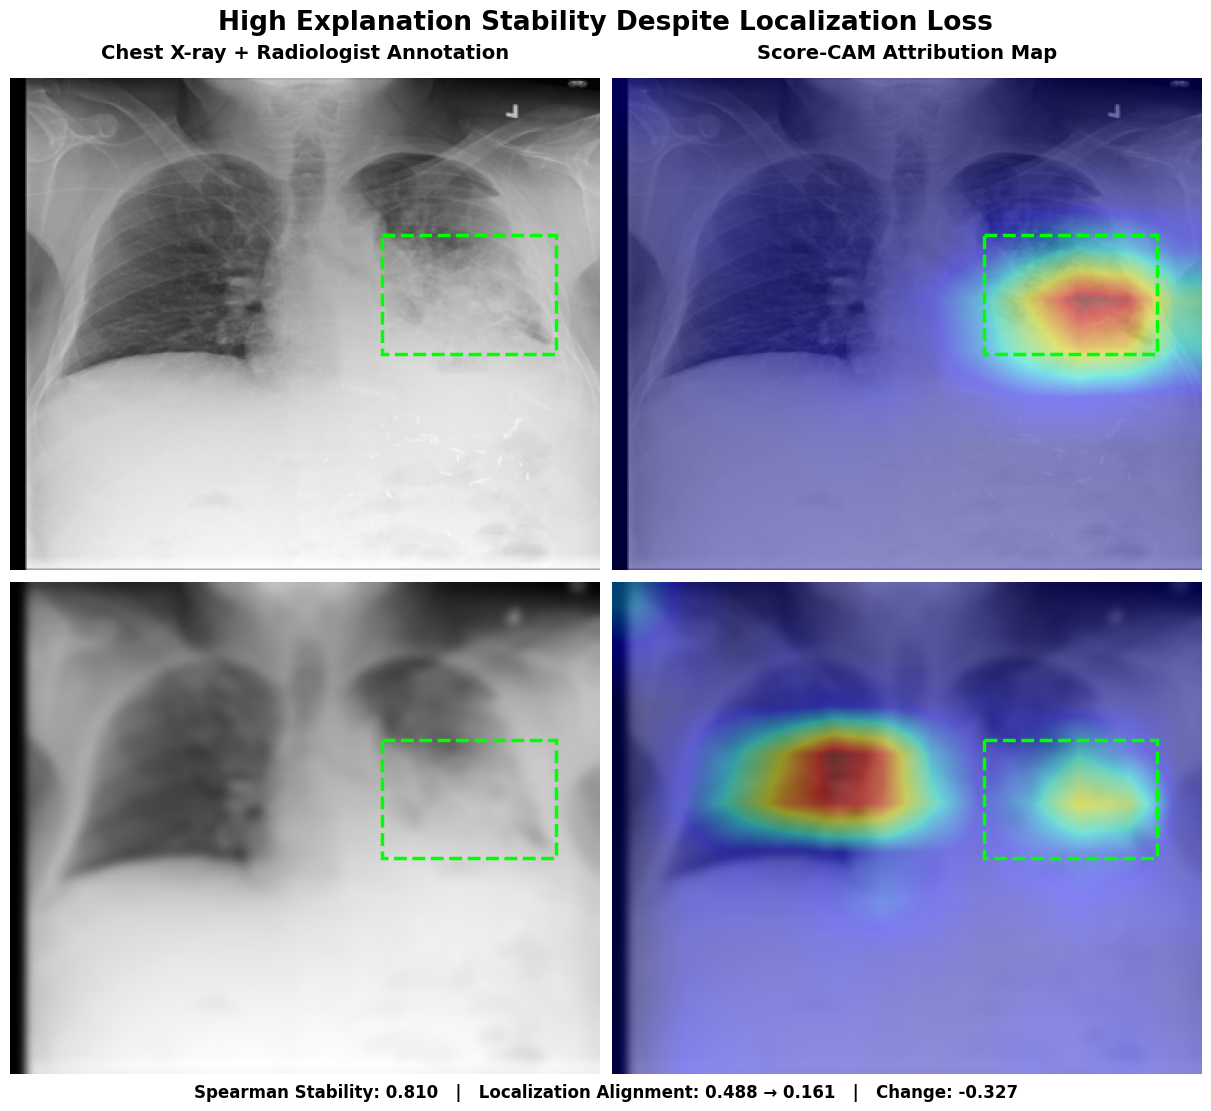

Saved: /content/drive/MyDrive/XAI_project_Expo_1_folder/Results/ExpandedEvaluation/flagged_disagreement_poster_final.png


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np

def normalize_map(heatmap):
    heatmap = np.abs(np.squeeze(np.asarray(heatmap, dtype=float)))
    return heatmap / (heatmap.max() + 1e-8)


def add_boxes(ax, boxes, image_shape):
    height, width = image_shape[:2]

    for annotation in boxes:
        b = annotation["data"]

        sx = width / annotation["width"]
        sy = height / annotation["height"]

        ax.add_patch(
            Rectangle(
                (b["x"] * sx, b["y"] * sy),
                b["width"] * sx,
                b["height"] * sy,
                linewidth=2.5,
                edgecolor="lime",
                linestyle="--",
                facecolor="none"
            )
        )


# Create figure with better spacing
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 11),
    constrained_layout=True
)

images = [original_image, corrupted_image]
maps = [original_map, corrupted_map]

# Column headings
column_titles = [
    "Chest X-ray + Radiologist Annotation",
    f"{method} Attribution Map"
]

for j in range(2):
    axes[0, j].set_title(
        column_titles[j],
        fontsize=14,
        fontweight="bold",
        pad=14
    )

# Plot original and corrupted images
for i in range(2):

    axes[i, 0].imshow(images[i], cmap="gray")
    add_boxes(axes[i, 0], boxes, images[i].shape)

    axes[i, 1].imshow(images[i], cmap="gray")
    axes[i, 1].imshow(
        normalize_map(maps[i]),
        cmap="jet",
        alpha=0.45,
        vmin=0,
        vmax=1
    )
    add_boxes(axes[i, 1], boxes, images[i].shape)

    for ax in axes[i]:
        ax.axis("off")

# Row labels
axes[0, 0].set_ylabel(
    "Original",
    fontsize=15,
    fontweight="bold",
    labelpad=15
)

axes[1, 0].set_ylabel(
    f"Corrupted\n{case['corruption']} ({case['severity']})",
    fontsize=15,
    fontweight="bold",
    labelpad=15
)

# Main title
fig.suptitle(
    "High Explanation Stability Despite Localization Loss",
    fontsize=19,
    fontweight="bold"
)

# Numerical findings
fig.supxlabel(
    (
        f"Spearman Stability: {case['explanation_similarity']:.3f}   |   "
        f"Localization Alignment: "
        f"{case['original_alignment']:.3f} → "
        f"{case['localization_alignment']:.3f}   |   "
        f"Change: {case['alignment_change']:.3f}"
    ),
    fontsize=12,
    fontweight="bold"
)

# Save poster-ready image
output_path = (
    EXPANDED_DIR / "flagged_disagreement_poster_final.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Saved:", output_path)

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from xai_utils import calculate_alignment

# 1. Recalculate explanation stability
recalculated_stability = spearmanr(
    np.asarray(original_map).ravel(),
    np.asarray(corrupted_map).ravel()
).statistic

# 2. Recalculate localization alignment
recalculated_original_alignment = calculate_alignment(
    original_map, boxes
)

recalculated_corrupted_alignment = calculate_alignment(
    corrupted_map, boxes
)

# 3. Recalculate alignment change
recalculated_change = (
    recalculated_corrupted_alignment
    - recalculated_original_alignment
)

# 4. Compare against saved audit results
validation = pd.DataFrame({
    "Metric": [
        "Explanation stability",
        "Original alignment",
        "Corrupted alignment",
        "Alignment change"
    ],
    "Saved audit": [
        case["explanation_similarity"],
        case["original_alignment"],
        case["localization_alignment"],
        case["alignment_change"]
    ],
    "Recalculated": [
        recalculated_stability,
        recalculated_original_alignment,
        recalculated_corrupted_alignment,
        recalculated_change
    ]
})

validation["Absolute difference"] = (
    validation["Saved audit"]
    - validation["Recalculated"]
).abs()

display(validation.round(6))

# Check numerical agreement
tolerance = 1e-3

if (validation["Absolute difference"] < tolerance).all():
    print("PASS: Regenerated explanations match the saved audit metrics.")
else:
    print("CHECK: Some regenerated metrics differ from the saved audit.")

,Metric,Saved audit,Recalculated,Absolute difference
0,Explanation stability,0.810481,0.810481,0.0
1,Original alignment,0.487917,0.487917,0.0
2,Corrupted alignment,0.161049,0.161049,0.0
3,Alignment change,-0.326868,-0.326868,0.0


PASS: Regenerated explanations match the saved audit metrics.


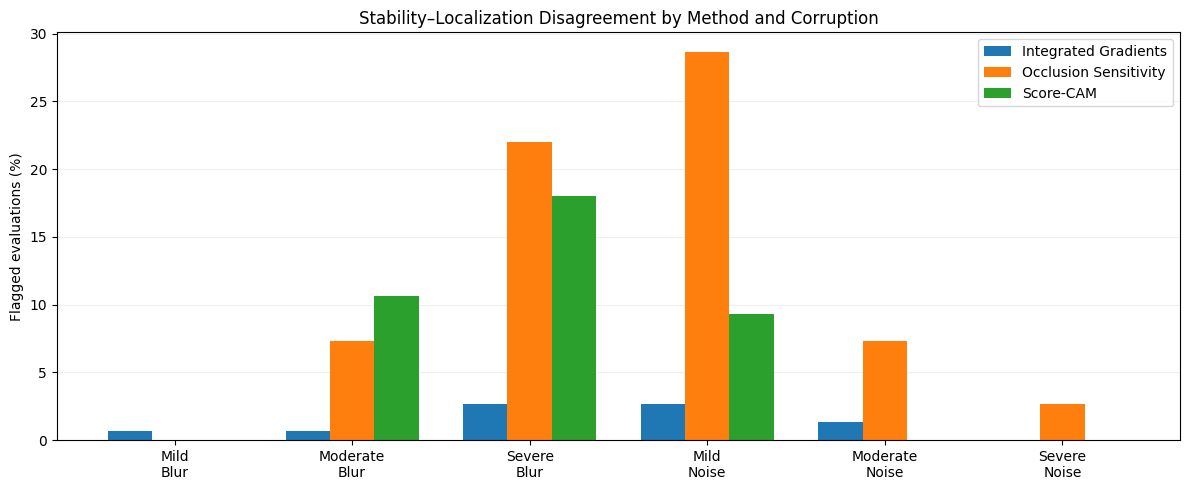

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

conditions = [
    ("Blur", "mild"),
    ("Blur", "moderate"),
    ("Blur", "severe"),
    ("Noise", "mild"),
    ("Noise", "moderate"),
    ("Noise", "severe"),
]

methods = [
    "Integrated Gradients",
    "Occlusion Sensitivity",
    "Score-CAM"
]

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(conditions))
width = 0.25

for i, method in enumerate(methods):
    rates = []

    for corruption, severity in conditions:
        rows = audit_summary.loc[
            (audit_summary["method"] == method)
            & (audit_summary["corruption"] == corruption)
            & (audit_summary["severity"] == severity)
        ]

        rates.append(
            rows["Disagreement_Rate_Pct"].iloc[0]
        )

    ax.bar(x + (i - 1) * width, rates, width, label=method)

ax.set_xticks(x)
ax.set_xticklabels(
    [f"{severity.title()}\n{corruption}" for corruption, severity in conditions]
)
ax.set_ylabel("Flagged evaluations (%)")
ax.set_title("Stability–Localization Disagreement by Method and Corruption")
ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    EXPANDED_DIR / "audit_disagreement_rates.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

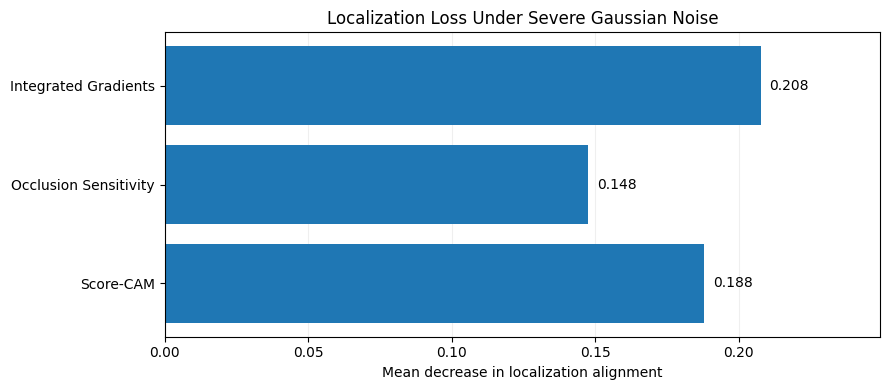

In [ ]:
import matplotlib.pyplot as plt

severe_noise = audit_df.loc[
    (audit_df["corruption"] == "Noise")
    & (audit_df["severity"] == "severe")
].copy()

summary = (
    severe_noise.groupby("method")["alignment_change"]
    .mean()
    .reindex(methods)
)

loss = -summary

fig, ax = plt.subplots(figsize=(9, 4))

bars = ax.barh(loss.index, loss.values)

for bar, value in zip(bars, loss.values):
    ax.text(
        value + 0.003,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.3f}",
        va="center"
    )

ax.set_xlabel("Mean decrease in localization alignment")
ax.set_title("Localization Loss Under Severe Gaussian Noise")
ax.invert_yaxis()
ax.set_xlim(0, max(loss.values) * 1.2)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    EXPANDED_DIR / "severe_noise_localization_loss.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

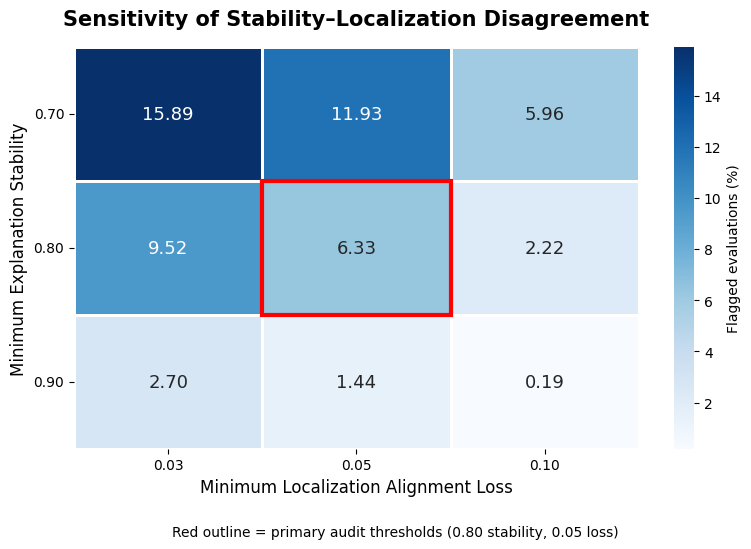

Heatmap saved to: /content/drive/MyDrive/XAI_project_Expo_1_folder/Results/ExpandedEvaluation/audit_threshold_sensitivity_heatmap.png


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Rectangle

# ==========================================
# Threshold Sensitivity Heatmap
# ==========================================

# Use results already calculated in Cell 88
heatmap_data = sensitivity_df.pivot(
    index="Stability_Threshold",
    columns="Loss_Threshold",
    values="Flagged_Rate_Pct"
)

# Arrange thresholds in ascending order
heatmap_data = heatmap_data.sort_index().sort_index(axis=1)

# Create heatmap
fig, ax = plt.subplots(figsize=(8, 5.5))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    linewidths=1,
    linecolor="white",
    cbar_kws={"label": "Flagged evaluations (%)"},
    annot_kws={"fontsize": 13},
    ax=ax
)

# ==========================================
# Highlight primary audit thresholds
# Stability >= 0.80 and loss >= 0.05
# ==========================================

row_index = list(heatmap_data.index).index(0.80)
col_index = list(heatmap_data.columns).index(0.05)

ax.add_patch(
    Rectangle(
        (col_index, row_index),
        1,
        1,
        fill=False,
        edgecolor="red",
        linewidth=3
    )
)

# Axis labels and title
ax.set_title(
    "Sensitivity of Stability–Localization Disagreement",
    fontsize=15,
    fontweight="bold",
    pad=16
)

ax.set_xlabel(
    "Minimum Localization Alignment Loss",
    fontsize=12
)

ax.set_ylabel(
    "Minimum Explanation Stability",
    fontsize=12
)

ax.set_xticklabels(["0.03", "0.05", "0.10"], rotation=0)
ax.set_yticklabels(["0.70", "0.80", "0.90"], rotation=0)

# Caption below the heatmap
fig.text(
    0.5,
    0.015,
    "Red outline = primary audit thresholds (0.80 stability, 0.05 loss)",
    ha="center",
    fontsize=10
)

plt.tight_layout(rect=[0, 0.06, 1, 1])

# Save figure
output_path = (
    EXPANDED_DIR / "audit_threshold_sensitivity_heatmap.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Heatmap saved to:", output_path)

## 11. Conclusions and Limitations

### Main Findings

The expanded evaluation demonstrates that explanation stability and localization alignment can diverge under image corruption.

Using the primary disagreement criterion of Spearman stability ≥ 0.80 and localization alignment decrease ≥ 0.05:

- 171 of 2,700 evaluations were flagged (6.33%).
- Among 1,076 high-stability evaluations, 171 (15.9%) also showed the specified localization loss.
- In 169 of the 171 flagged evaluations (98.83%), the classifier's predicted class remained unchanged.

These findings indicate that preserving an explanation's spatial-ranking structure does not necessarily preserve its alignment with annotated opacity regions.

The disagreement frequency varied by explanation method and corruption condition. For example, Occlusion Sensitivity under mild Gaussian noise produced the highest flagged rate in the primary audit (43 of 150 annotated positive images, or 28.67%). Under severe Gaussian noise, substantial localization deterioration could occur without satisfying the high-stability requirement, illustrating why disagreement frequency should not be interpreted as a complete measure of corruption-induced explanation damage.


### Limitations

- The evaluation uses one ResNet-50 classifier and one chest X-ray dataset.
- Only three post-hoc explanation methods are compared.
- Gaussian blur and Gaussian noise represent a limited set of image corruptions.
- Radiologist bounding boxes are imperfect proxies for clinically relevant image regions.
- The disagreement thresholds are exploratory.
- Repeated evaluations from the same images are statistically dependent.
- Stability and localization alignment do not directly establish explanation faithfulness or clinical correctness.
- The evaluation does not establish how the findings generalize to other hospitals, scanners, patient populations, or diagnostic tasks.

### Future Work

I want to investigate whether the disagreement patterns differ between correctly and incorrectly classified cases. This would help clarify how model performance affects the interpretation of explanation localization.

### Reproducibility

The analysis relies on the saved model checkpoint, the 300-image sample manifest, radiologist annotation files, shared `xai_utils.py` utilities, and the per-image results generated for all three explanation methods.

Some computations use cached per-image CSV files and batch-limited execution to accommodate Google Colab runtime constraints.

Reproducing the analysis requires checking that cached files were generated with the same model checkpoint, preprocessing, attribution settings, and corruption parameters.

The notebook also contains exploratory diagnostics and recovery code reflecting the iterative development process.


## Consolidated References

1. Sundararajan, M., Taly, A., & Yan, Q. (2017). Axiomatic attribution for deep networks. *Proceedings of the 34th International Conference on Machine Learning*, 3319–3328. https://proceedings.mlr.press/v70/sundararajan17a.html

2. Zeiler, M. D., & Fergus, R. (2014). Visualizing and understanding convolutional networks. *European Conference on Computer Vision*, 818–833. https://doi.org/10.1007/978-3-319-10590-1_53

3. Wang, H., Wang, Z., Du, M., Yang, F., Zhang, Z., Ding, S., Mardziel, P., & Hu, X. (2020). Score-CAM: Score-weighted visual explanations for convolutional neural networks. *Proceedings of the IEEE/CVF Conference on Computer Vision and Pattern Recognition Workshops*.

4. Talaat, M., Si, X., & Xi, J. (2023). Multi-level training and testing of CNN models in diagnosing multi-center COVID-19 and pneumonia X-ray images. *Applied Sciences, 13*(18), 10270. https://doi.org/10.3390/app131810270

